# 08 — Análisis de observabilidad de `sin_camara`

**Plan de notebooks, uno por número.** El 07 justifica por qué EP2 usa `sin_camara` y lo compara con las otras opciones; **el 08 (este) analiza los datos del target elegido**; el 09 entrena los modelos supervisados; el 10 evalúa en el test y cierra.

**Qué hacemos acá.** El 07 decidió que EP2 predice `sin_camara` (cajas 3D etiquetadas de peatones y ciclistas dentro de la zona de cámaras que no tienen su par 2D de cámara).
Acá entendemos **qué produce esa etiqueta**, probamos si hay variables que la regla simple "menos puntos LiDAR primero" no tiene, y armamos el análisis no supervisado orientado a B.
Es insumo del notebook 09; **no entrena el modelo final ni elige puntos de operación** (eso es del 09).

**Reglas.** Solo segmentos de **train** y los folds de `train.parquet`. El test no se carga. Todas las cifras se calculan en el notebook y los textos de conclusión se generan con f-strings.
Los umbrales de la Sección 0 se fijaron **antes de correr este notebook** y no se cambian. Si una prueba no mejora nada, lo reportamos tal cual.

**Entradas:** `train.parquet`, `config_features.json`, `waymo_con_target` (catálogo Kedro, filtrado a segmentos de train; se necesita para el historial de cada objeto y las cajas vecinas de cada frame).
**Salidas:** `data/05_model_input/features_B.parquet` y `config_features_B.json` (insumo del 09), `images/08_*.png`, `data/08_reporting/08_*.csv`, `docs/analisis_observabilidad_B.md`.

<a id="resumen"></a>
## Resumen ejecutivo

*(Texto generado por la celda "Resumen ejecutivo generado" en la última ejecución; se copia acá para leerlo arriba. Si se vuelve a ejecutar el notebook, hay que volver a copiarlo.)*

**Qué produce `sin_camara`.** La tasa va de 80,5 % con 0-5 puntos a 9,4 % con >100. El cambio es gradual: el mejor corte único (7 puntos) logra AUC 0,665 frente a 0,797 de la regla continua y su ubicación varía entre folds. Dentro de un mismo objeto, el 80,0 % de los objetos mixtos tiene más puntos en los frames con par 2D (Wilcoxon p = 1.9e-29), aunque la distancia también cambia.

**Puntos clave**

1. **Robustez.** La mediana del AUC por segmento del HGB es 0,864 (IQR 0,818–0,913, 16 segmentos evaluables) frente a 0,854 agrupado; la regla simple tiene 0,802 por segmento y 0,797 agrupado.
2. **Variables nuevas.** Ningún conjunto cumple el criterio fijado antes (ΔAUC ≥ 0,01 y fracción para 80 % −2 puntos con IC que excluya 0): la regla "pocos puntos" explica casi todo y el modelo agrega solo la parte ya medida en el 07. Mejor AUC: TODAS_B + ambos (0,861).
3. **No supervisado.** k = 2, silhouette 0,387, estabilidad ARI 0,953 (mínimo 0,301), rango de la tasa entre clusters 12,4 puntos y diferencia con signo de 12,4 puntos (IC 7,6 a 18,2): estructura útil según el criterio; las probabilidades del modelo ya siguen esas tasas, así que describe pero no agrega información predictiva.

**Qué llevar al 09.** Variables: `TODAS_B` (conjunto base, porque ningún conjunto ampliado cumplió el criterio). Modelos: la regresión logística y el HGB se comparan en el 09 (AUC agrupado HGB 0,854 contra regresión logística 0,838; mediana del AUC por segmento HGB 0,864 contra regresión logística 0,873), siempre contra la regla simple de menos puntos LiDAR primero (AUC 0,797), que es la alternativa realista; **la decisión se toma ahí**. Las variables quedan en `data/05_model_input/features_B.parquet` y los conjuntos en `config_features_B.json`.

Este notebook no entrena el modelo final ni elige puntos de operación; es insumo del 09.

## Lecturas tomadas en el parche A.6 (decisiones sin consulta)

Este parche se hizo sin poder consultar; ante cada ambigüedad se tomó la lectura más razonable:

1. **"Reevaluar excluyendo la franja 100-120"** se interpretó como evaluar las predicciones fuera de fold que ya existen (modelos entrenados con toda B) **solo en las filas con azimut ≤ 100**, con los mismos folds y el mismo bootstrap por segmentos. El reentrenamiento solo con esa población se hace en el notebook 09 (sección H).
2. **El cruce de clusters con la franja** depende de los clusters de la Sección D, que se calculan más abajo; por eso esa parte de A.6 está al final de D (D.2). No se modificaron ni `features_B.parquet` ni `config_features_B.json`.
3. **Documentación de Waymo:** solo se afirma lo que se pudo verificar; las orientaciones de montaje de las cámaras no se pudieron leer y no se inventan.
4. **Nueva pasada (población principal):** el componente `camera_calibration` no existe en los datos locales; la sección A.7 lo verifica por código y, como complemento, usa la tabla de asociación (`key.camera_name`) para ver por cámara el azimut de las cajas asociadas. **Eso no es calibración:** no da yaw ni campo de visión.
   `AZ_MAX = 100` es el límite de la población principal (se eligió antes de A.7 y no se cambia acá). Los cambios de E.1 y E.2 y la exportación de `en_zona_principal` se hicieron en la misma pasada que A.7.

## Sección 0 — Criterios fijados antes de correr

**Por qué importa.** Si los umbrales se eligen después de ver los resultados, cualquier variable o agrupamiento se puede declarar "útil". Estos se escribieron antes de ejecutar nada.

- **Variable nueva "ayuda"** si el conjunto ampliado mejora el AUC fuera de fold en ≥ 0,01 sobre `TODAS_B` **y** la Fracción para 80 % baja ≥ 2 puntos, con IC 95 % por segmentos (bootstrap pareado) que excluya 0 en ambos casos.
- **Estructura no supervisada "útil"** si silhouette ≥ 0,25, ARI de estabilidad por segmento ≥ 0,80 y el rango de la tasa de `sin_camara` entre clusters ≥ 10 puntos con IC que excluya 0.
- **Lectura operativa (también fijada antes):** el corte único de puntos es "marcado" si su AUC fuera de fold es ≥ el de la regla continua − 0,05 y el rango de su umbral entre folds es ≤ 25 % de su mediana; un segmento es "evaluable" para el AUC por segmento si tiene ≥ 200 filas de cada clase (si hay menos de 10 segmentos evaluables se relaja a 100).

In [1]:
CRIT = {
    "variable_nueva": {"delta_auc_min": 0.01, "delta_fraccion80_max": -0.02},
    "estructura": {"silhouette_min": 0.25, "ari_min": 0.80, "rango_tasa_min_pp": 10.0},
    "umbral_marcado": {"margen_auc": 0.05, "rango_umbral_rel_max": 0.25},
    "auc_segmento": {"min_filas_clase": 200, "min_segmentos": 10, "min_filas_clase_relajado": 100},
}
print(CRIT)

{'variable_nueva': {'delta_auc_min': 0.01, 'delta_fraccion80_max': -0.02}, 'estructura': {'silhouette_min': 0.25, 'ari_min': 0.8, 'rango_tasa_min_pp': 10.0}, 'umbral_marcado': {'margen_auc': 0.05, 'rango_umbral_rel_max': 0.25}, 'auc_segmento': {'min_filas_clase': 200, 'min_segmentos': 10, 'min_filas_clase_relajado': 100}}


## Configuración y carga

Mismas rutas y funciones `cargar` / `guardar_fig` que los notebooks 06 y 07.

In [2]:
from pathlib import Path
import json
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from scipy.stats import wilcoxon
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.decomposition import PCA
from sklearn.ensemble import HistGradientBoostingClassifier, IsolationForest
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (adjusted_rand_score, average_precision_score, calinski_harabasz_score, davies_bouldin_score,
                             roc_auc_score, silhouette_score)
from sklearn.mixture import GaussianMixture
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import RobustScaler, StandardScaler
from sklearn.tree import DecisionTreeClassifier

SEMILLA = 42
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 170)

try:
    RAIZ = Path(context.project_path)
except NameError:
    RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "conf").exists() and (p / "data").exists())

RUTA_IMAGENES = RAIZ / "images"
RUTA_MODEL_INPUT = RAIZ / "data" / "05_model_input"
RUTA_REPORTING = RAIZ / "data" / "08_reporting"
RUTA_DOCS = RAIZ / "docs"
RUTA_IMAGENES.mkdir(exist_ok=True)
RUTA_REPORTING.mkdir(parents=True, exist_ok=True)


def cargar(nombre, ruta_relativa):
    # Carga desde el catalogo de Kedro; si no hay catalogo, lee el archivo directo.
    try:
        return catalog.load(nombre)
    except NameError:
        ruta = RAIZ / ruta_relativa
        return pd.read_csv(ruta) if ruta.suffix == ".csv" else pd.read_parquet(ruta)


def guardar_fig(fig, nombre):
    fig.savefig(RUTA_IMAGENES / f"{nombre}.png", dpi=150, bbox_inches="tight")


def pct(x, d=1):
    return f"{x * 100:.{d}f} %".replace(".", ",")


def n2(x, d=2):
    return f"{x:.{d}f}".replace(".", ",")


def miles(x):
    return f"{int(x):,}".replace(",", ".")


def md_tabla(df, indice=True):
    d = df.reset_index() if indice else df
    cab = "| " + " | ".join(map(str, d.columns)) + " |\n|" + "---|" * len(d.columns) + "\n"
    return cab + "\n".join("| " + " | ".join(str(v) for v in fila) + " |" for fila in d.values)


AZUL, NARANJA, GRIS, VERDE = "#2a78d6", "#e07b39", "#8a8a8a", "#6a994e"
VRU = ["PEDESTRIAN", "CYCLIST"]
ZONA_CAMARAS_DEG = 120
AZ_MAX = 100          # limite de la poblacion principal (definido despues del hallazgo de A.6; no cambia el target ni el split)
RES = {}

In [3]:
config = json.loads((RUTA_MODEL_INPUT / "config_features.json").read_text(encoding="utf-8"))
FEATURES_NUM, TARGET, GRUPO = config["features_num"], config["target"], config["grupo"]
SEGS_TEST = set(config["segmentos_test"])

train = pd.read_parquet(RUTA_MODEL_INPUT / "train.parquet")
SEGS_TRAIN = sorted(train[GRUPO].unique())
assert SEGS_TEST.isdisjoint(SEGS_TRAIN), "Hay segmentos de test en train"
assert (train.groupby(GRUPO)["fold"].nunique() == 1).all()
FOLDS = [int(k) for k in sorted(train["fold"].unique())]

# waymo_con_target: todos los frames de los segmentos de train (historial de cada objeto y cajas vecinas de cada frame)
completo = cargar("waymo_con_target", "data/02_intermediate/waymo_con_target.parquet")
completo = completo[completo["segment_id"].isin(SEGS_TRAIN)].reset_index(drop=True)
assert SEGS_TEST.isdisjoint(completo["segment_id"].unique())
completo["fi"] = completo.groupby("segment_id")["key.frame_timestamp_micros"].rank(method="dense").astype(int) - 1
completo["_h"] = completo["[LiDARBoxComponent].box.heading"]

# Poblacion de B: peatones y ciclistas con |azimut| <= 120 en frames etiquetados (solo train)
bz = train[train["object_type"].isin(VRU) & (train["azimut_abs_deg"] <= ZONA_CAMARAS_DEG)].reset_index(drop=True)
bz["es_ciclista"] = (bz["object_type"] == "CYCLIST").astype(int)
n0 = len(bz)
bz = bz.merge(completo[[GRUPO, "key.frame_timestamp_micros", "key.laser_object_id", "fi", "_h"]],
              on=[GRUPO, "key.frame_timestamp_micros", "key.laser_object_id"], how="left")
assert len(bz) == n0 and bz["fi"].notna().all()
bz["fi"] = bz["fi"].astype(int)
yB, fB = (1 - bz[TARGET]).values, bz["fold"].values
bz["sin"] = yB
TODAS_B = FEATURES_NUM + ["es_ciclista"]
REGLA = "Regla: menos puntos LiDAR primero"
print(f"Poblacion B (train): {len(bz):,} filas | {bz[GRUPO].nunique()} segmentos | prevalencia de sin_camara {yB.mean():.3f} | "
      f"objetos distintos: {bz.groupby([GRUPO, 'key.laser_object_id']).ngroups:,} | completo: {len(completo):,} filas")

[10/17/26 21:55:36] INFO     Loading data from waymo_con_target (ParquetDataset)...            ]8;id=9584950;file://C:\Users\maico\waymo-evaluacion\.venv\lib\site-packages\kedro\io\data_catalog.py\data_catalog.py]8;;\:]8;id=9584951;file://C:\Users\maico\waymo-evaluacion\.venv\lib\site-packages\kedro\io\data_catalog.py#1050\1050]8;;\

Poblacion B (train): 68,555 filas | 33 segmentos | prevalencia de sin_camara 0.232 | objetos distintos: 705 | completo: 393,698 filas


In [4]:
# ---- Funciones del notebook 07 (mismos folds, mismas curvas de captura y mismo bootstrap por segmento)
def oof_clasificador(X, y, folds, **kw):
    oof = np.zeros(len(X))
    for k in sorted(np.unique(folds)):
        tr, va = folds != k, folds == k
        m = HistGradientBoostingClassifier(max_iter=150, random_state=SEMILLA, **kw)
        m.fit(X[tr], y[tr])
        oof[va] = m.predict_proba(X[va])[:, 1]
    return oof


def auc_pr(y, s):
    if len(np.unique(y)) < 2:
        return np.nan, np.nan
    return roc_auc_score(y, s), average_precision_score(y, s)


def por_fold(y, s, folds):
    return np.array([auc_pr(y[folds == k], s[folds == k]) for k in sorted(np.unique(folds))])


def curva_cap(peso, score, tb):
    o = np.lexsort((tb, -score))
    return np.cumsum(peso[o]) / peso.sum()


def metr(cum):
    n = len(cum)
    en = lambda f: cum[max(int(np.ceil(f * n)) - 1, 0)]
    return {"Captura@10%": en(0.1), "Captura@20%": en(0.2), "Captura@30%": en(0.3), "Lift@20%": en(0.2) / 0.2, "Fraccion para 80%": (np.searchsorted(cum, 0.8) + 1) / n}


rng_g = np.random.default_rng(SEMILLA)
tb_f = rng_g.random(len(bz))                       # desempate aleatorio fijo para empates de puntaje
seg_codes, seg_nombres = pd.factorize(bz[GRUPO])
S_N = len(seg_nombres)
idx_seg = [np.where(seg_codes == s)[0] for s in range(S_N)]
N_BOOT = 300


def metricas_score(y, s, tb):
    auc, pr = auc_pr(y, s)
    m = metr(curva_cap(y.astype(float), s, tb))
    return {"AUC": auc, "PR-AUC": pr, "Captura@20%": m["Captura@20%"], "Fraccion para 80%": m["Fraccion para 80%"]}


def evaluar_boot(scores, ref=None, n_boot=N_BOOT, seed=SEMILLA):
    # Puntos, IC 95% por bootstrap de segmentos y diferencias pareadas contra `ref`.
    rng = np.random.default_rng(seed)
    punto = {n: metricas_score(yB, s, tb_f) for n, s in scores.items()}
    boot = {n: [] for n in scores}
    for _ in range(n_boot):
        ii = np.concatenate([idx_seg[s] for s in rng.integers(0, S_N, S_N)])
        if len(np.unique(yB[ii])) < 2:
            continue
        for n, s in scores.items():
            boot[n].append(metricas_score(yB[ii], s[ii], tb_f[ii]))
    filas = []
    for n in scores:
        b = pd.DataFrame(boot[n])
        fila = {"conjunto": n}
        for met in ["AUC", "PR-AUC", "Captura@20%", "Fraccion para 80%"]:
            fila[met] = punto[n][met]
            fila[met + " lo"], fila[met + " hi"] = np.percentile(b[met], [2.5, 97.5])
        if ref is not None and n != ref:
            bref = pd.DataFrame(boot[ref])
            for met in ["AUC", "Fraccion para 80%"]:
                d = b[met].values - bref[met].values
                fila["d" + met], (fila["d" + met + " lo"], fila["d" + met + " hi"]) = punto[n][met] - punto[ref][met], np.percentile(d, [2.5, 97.5])
        filas.append(fila)
    return pd.DataFrame(filas).set_index("conjunto")


def tasa_ci(etiqueta, n_boot=N_BOOT, seed=SEMILLA):
    # Tasa de sin_camara por categoria con IC 95% por bootstrap de segmentos. Devuelve la tabla y las tasas remuestreadas.
    et = pd.Series(etiqueta)
    if not isinstance(et.dtype, pd.CategoricalDtype):
        et = et.astype("category")                  # si ya es categorica se conservan las categorias y su orden
    cats, codes = list(et.cat.categories), et.cat.codes.values
    ok = codes >= 0
    n = np.zeros((S_N, len(cats)))
    k = np.zeros_like(n)
    np.add.at(n, (seg_codes[ok], codes[ok]), 1)
    np.add.at(k, (seg_codes[ok], codes[ok]), yB[ok])
    idx = np.random.default_rng(seed).integers(0, S_N, (n_boot, S_N))
    Nb, Kb = n[idx].sum(1), k[idx].sum(1)
    tasas = Kb / np.where(Nb > 0, Nb, np.nan)
    with np.errstate(invalid="ignore", divide="ignore"):
        punto = k.sum(0) / n.sum(0)
    tab = pd.DataFrame({"filas": n.sum(0).astype(int), "tasa": punto, "lo": np.nanpercentile(tasas, 2.5, axis=0), "hi": np.nanpercentile(tasas, 97.5, axis=0)}, index=[str(c) for c in cats])
    return tab, tasas


# Modelos de referencia del 07 (todas las variables), regresion logistica y regla simple
s_hgb = oof_clasificador(bz[TODAS_B].values, yB, fB)
XL = bz[TODAS_B].copy()
for col in ["num_lidar_points", "num_top_lidar_points", "densidad_puntos", "volumen_caja"]:
    XL[col] = np.log1p(XL[col].clip(lower=0))
s_lr = np.zeros(len(bz))
for k in FOLDS:
    tr, va = fB != k, fB == k
    s_lr[va] = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)).fit(XL.values[tr], yB[tr]).predict_proba(XL.values[va])[:, 1]
s_regla = -bz["num_lidar_points"].values.astype(float)
auc_base = {"HGB": auc_pr(yB, s_hgb)[0], "Regresion logistica": auc_pr(yB, s_lr)[0], REGLA: auc_pr(yB, s_regla)[0]}
print("AUC fuera de fold (referencia, igual al 07):", {k: round(v, 3) for k, v in auc_base.items()})

AUC fuera de fold (referencia, igual al 07): {'HGB': 0.854, 'Regresion logistica': 0.838, 'Regla: menos puntos LiDAR primero': 0.797}


# A. Qué determina `sin_camara`

**Por qué importa.** En el 07 vimos que sin los puntos LiDAR el AUC cae de 0,854 a 0,654. Antes de buscar más variables, miramos con detalle **cómo** depende la etiqueta de los puntos, la distancia y la clase.

## A.1 Tasa de `sin_camara` según puntos LiDAR, clase y distancia

Intervalos de confianza por bootstrap de segmentos.

Tasa de sin_camara por deciles de puntos LiDAR:
                 filas   tasa     lo     hi
(-0.001, 3.0]     7282  0.854  0.721  0.917
(3.0, 11.0]       7346  0.441  0.314  0.540
(11.0, 18.0]      6407  0.202  0.141  0.285
(18.0, 27.0]      6639  0.147  0.097  0.213
(27.0, 38.0]      6876  0.141  0.086  0.193
(38.0, 54.0]      6825  0.107  0.067  0.145
(54.0, 80.0]      6696  0.086  0.053  0.116
(80.0, 129.0]     6798  0.085  0.046  0.117
(129.0, 250.0]    6837  0.077  0.041  0.122
(250.0, 7097.0]   6849  0.113  0.059  0.167

Por bins fijos de puntos:
        filas   tasa     lo     hi
0-5      9135  0.805  0.659  0.880
6-10     4540  0.402  0.286  0.504
11-20    9078  0.201  0.139  0.283
21-50   17199  0.132  0.086  0.180
51-100  11557  0.087  0.054  0.116
>100    17046  0.094  0.056  0.134

Por bins fijos de puntos, solo PEDESTRIAN:
        filas   tasa     lo     hi
0-5      9053  0.807  0.660  0.883
6-10     4494  0.406  0.288  0.509
11-20    8972  0.203  0.141  0.286
21-50   1683

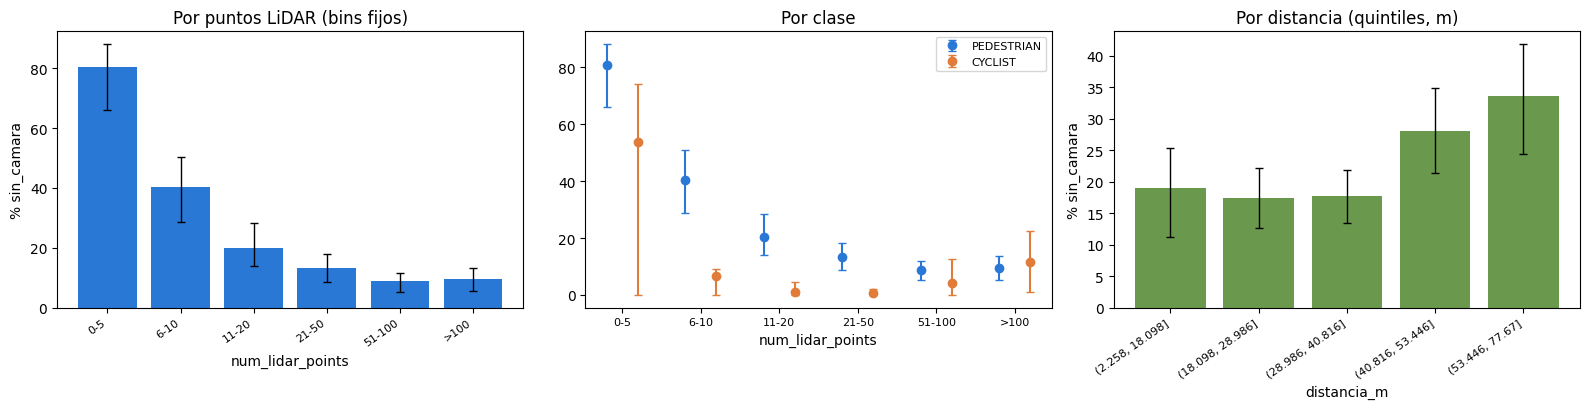

In [5]:
pts = bz["num_lidar_points"]
bins_fijos = [-1, 5, 10, 20, 50, 100, np.inf]
et_fijos = ["0-5", "6-10", "11-20", "21-50", "51-100", ">100"]
bz["pts_fijo"] = pd.cut(pts, bins_fijos, labels=et_fijos)
bz["pts_decil"] = pd.qcut(pts, 10, duplicates="drop")
bz["dist_q5"] = pd.qcut(bz["distancia_m"], 5)

t_decil, _ = tasa_ci(bz["pts_decil"])
t_fijo, _ = tasa_ci(bz["pts_fijo"])
t_dist, _ = tasa_ci(bz["dist_q5"])
t_clase = {c: tasa_ci(bz["pts_fijo"].where(bz["object_type"] == c)) for c in VRU}
assert list(t_fijo.index) == et_fijos, f"orden de bins incorrecto: {list(t_fijo.index)}"
assert all(list(t_clase[c][0].index) == et_fijos for c in VRU), "orden de bins por clase incorrecto"
print("Tasa de sin_camara por deciles de puntos LiDAR:")
print(t_decil.round(3).to_string())
print("\nPor bins fijos de puntos:")
print(t_fijo.round(3).to_string())
for c in VRU:
    print(f"\nPor bins fijos de puntos, solo {c}:")
    print(t_clase[c][0].round(3).to_string())
print("\nPor distancia (quintiles):")
print(t_dist.round(3).to_string())

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
def barras_ic(ax, t, titulo, xl, color=AZUL):
    x = np.arange(len(t))
    ax.bar(x, t["tasa"] * 100, color=color)
    ax.errorbar(x, t["tasa"] * 100, yerr=[(t["tasa"] - t["lo"]) * 100, (t["hi"] - t["tasa"]) * 100], fmt="none", color="k", capsize=3, lw=1)
    ax.set_xticks(x, t.index, rotation=35, ha="right", fontsize=8); ax.set_xlabel(xl); ax.set_ylabel("% sin_camara"); ax.set_title(titulo)
barras_ic(axes[0], t_fijo, "Por puntos LiDAR (bins fijos)", "num_lidar_points")
for c, col, off in [("PEDESTRIAN", AZUL, -0.2), ("CYCLIST", NARANJA, 0.2)]:
    t = t_clase[c][0]
    x = np.arange(len(t)) + off
    axes[1].errorbar(x, t["tasa"] * 100, yerr=[(t["tasa"] - t["lo"]).fillna(0) * 100, (t["hi"] - t["tasa"]).fillna(0) * 100], fmt="o", color=col, capsize=3, label=c)
axes[1].set_xticks(range(len(et_fijos)), et_fijos, fontsize=8); axes[1].set_xlabel("num_lidar_points"); axes[1].set_title("Por clase"); axes[1].legend(fontsize=8)
barras_ic(axes[2], t_dist, "Por distancia (quintiles, m)", "distancia_m", color=VERDE)
fig.tight_layout()
guardar_fig(fig, "08_tasa_por_puntos_clase_distancia")
plt.show()
t_fijo.to_csv(RUTA_REPORTING / "08_tasa_por_puntos.csv")
RES["tasa_fijo"], RES["tasa_dist"] = t_fijo, t_dist

In [6]:
f, d = t_fijo, t_dist
display(Markdown(
    f"**Lectura (generada).** La tasa de `sin_camara` va de {pct(f['tasa'].iloc[0])} entre las cajas con {f.index[0]} puntos a {pct(f['tasa'].iloc[-1])} entre las de {f.index[-1]} puntos "
    f"(IC 95 % de los extremos: {pct(f['lo'].iloc[0])}–{pct(f['hi'].iloc[0])} y {pct(f['lo'].iloc[-1])}–{pct(f['hi'].iloc[-1])}). "
    f"Por distancia, de {pct(d['tasa'].iloc[0])} en el quintil más cercano a {pct(d['tasa'].iloc[-1])} en el más lejano. "
    f"Los ciclistas tienen pocas filas por bin ({int(t_clase['CYCLIST'][0]['filas'].min())} a {int(t_clase['CYCLIST'][0]['filas'].max())}), así que sus intervalos son anchos."))

**Lectura (generada).** La tasa de `sin_camara` va de 80,5 % entre las cajas con 0-5 puntos a 9,4 % entre las de >100 puntos (IC 95 % de los extremos: 65,9 %–88,0 % y 5,6 %–13,4 %). Por distancia, de 19,0 % en el quintil más cercano a 33,6 % en el más lejano. Los ciclistas tienen pocas filas por bin (46 a 624), así que sus intervalos son anchos.

## A.2 Mapa de calor: puntos × distancia

Muestra si los puntos importan por sí solos o porque los objetos lejanos tienen menos puntos.

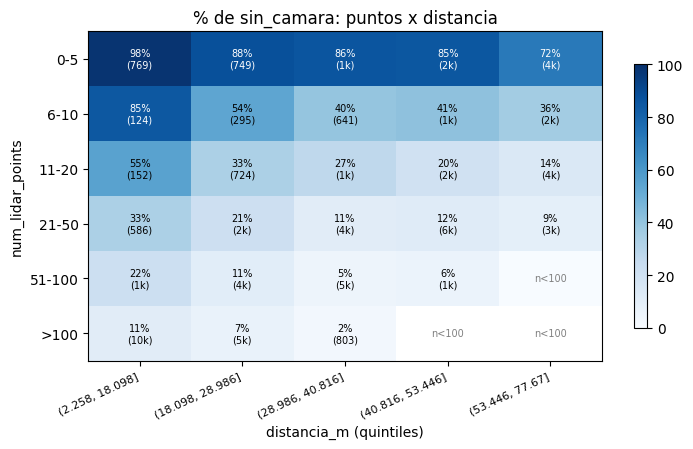

Diferencia de tasa (puntos bajos menos puntos altos) dentro de cada quintil de distancia (pp): {'(2.258, 18.098]': np.float64(87.1), '(18.098, 28.986]': np.float64(81.1), '(28.986, 40.816]': np.float64(83.4), '(40.816, 53.446]': np.float64(78.9), '(53.446, 77.67]': np.float64(71.7)}


**Lectura (generada).** Dentro de cada quintil de distancia, la tasa de `sin_camara` entre las cajas con menos puntos supera a la de las cajas con más puntos por 71,7 a 87,1 puntos porcentuales: el efecto de los puntos persiste a distancia fija, no es solo un efecto de la distancia.

In [7]:
tab_h = bz.groupby(["pts_fijo", "dist_q5"], observed=True)["sin"].agg(["mean", "size"]).reset_index()
mat = tab_h.pivot(index="pts_fijo", columns="dist_q5", values="mean") * 100
cnt = tab_h.pivot(index="pts_fijo", columns="dist_q5", values="size")
fig, ax = plt.subplots(figsize=(7.5, 4.6))
im = ax.imshow(mat.values.astype(float), cmap="Blues", aspect="auto", vmin=0, vmax=100)
ax.set_xticks(range(mat.shape[1]), [str(c) for c in mat.columns], rotation=25, ha="right", fontsize=8)
ax.set_yticks(range(mat.shape[0]), [str(i) for i in mat.index])
for i in range(mat.shape[0]):
    for j in range(mat.shape[1]):
        n = cnt.values[i, j]
        if np.isnan(n) or n < 100:
            ax.text(j, i, "n<100", ha="center", va="center", fontsize=7, color="gray")
        else:
            ax.text(j, i, f"{mat.values[i, j]:.0f}%\n({int(n) // 1000}k)" if n >= 1000 else f"{mat.values[i, j]:.0f}%\n({int(n)})", ha="center", va="center", fontsize=7,
                    color="white" if mat.values[i, j] > 60 else "black")
ax.set_xlabel("distancia_m (quintiles)"); ax.set_ylabel("num_lidar_points"); ax.set_title("% de sin_camara: puntos x distancia")
fig.colorbar(im, ax=ax, shrink=0.8)
fig.tight_layout()
guardar_fig(fig, "08_mapa_puntos_distancia")
plt.show()
# Dentro de cada quintil de distancia, ¿sigue cayendo la tasa al subir los puntos?
caida = {str(c): (mat[c].dropna().iloc[0] - mat[c].dropna().iloc[-1]) for c in mat.columns}
RES["caida"] = (min(caida.values()), max(caida.values()))
print("Diferencia de tasa (puntos bajos menos puntos altos) dentro de cada quintil de distancia (pp):", {k: round(v, 1) for k, v in caida.items()})
display(Markdown(
    f"**Lectura (generada).** Dentro de cada quintil de distancia, la tasa de `sin_camara` entre las cajas con menos puntos supera a la de las cajas con más puntos por "
    f"{n2(min(caida.values()), 1)} a {n2(max(caida.values()), 1)} puntos porcentuales: " +
    ("el efecto de los puntos persiste a distancia fija, no es solo un efecto de la distancia." if min(caida.values()) > 0 else "en algún quintil el efecto de los puntos no se sostiene a distancia fija.")))

## A.3 ¿Hay un umbral de puntos o un cambio gradual?

Un árbol de decisión de profundidad 1 (un solo corte sobre `num_lidar_points`), ajustado fuera de fold. Criterio de lectura fijado antes: "marcado" si su AUC es ≥ el de la regla continua − 0,05 y el umbral es estable entre folds (rango ≤ 25 % de la mediana).

In [8]:
X1 = bz[["num_lidar_points"]].values
umbrales, oof_st = [], np.zeros(len(bz))
for k in FOLDS:
    tr, va = fB != k, fB == k
    t = DecisionTreeClassifier(max_depth=1, min_samples_leaf=200, random_state=SEMILLA).fit(X1[tr], yB[tr])
    umbrales.append(float(t.tree_.threshold[0]))
    oof_st[va] = t.predict_proba(X1[va])[:, 1]
auc_st = auc_pr(yB, oof_st)[0]
auc_cont = auc_base[REGLA]
umbral_med = float(np.median(umbrales))
rango_rel = (max(umbrales) - min(umbrales)) / umbral_med if umbral_med else np.nan
bajo, alto = bz.loc[pts <= umbral_med, "sin"].mean(), bz.loc[pts > umbral_med, "sin"].mean()
marcado = bool(auc_st >= auc_cont - CRIT["umbral_marcado"]["margen_auc"] and rango_rel <= CRIT["umbral_marcado"]["rango_umbral_rel_max"])
RES["umbral"] = {"umbrales": umbrales, "mediana": umbral_med, "rango_rel": rango_rel, "auc_corte": auc_st, "auc_continua": auc_cont, "marcado": marcado, "tasa_bajo": bajo, "tasa_alto": alto}
print(f"Umbrales por fold: {[round(u, 1) for u in umbrales]} | mediana {umbral_med:.1f} | rango relativo {rango_rel:.2f}")
print(f"AUC del corte unico: {auc_st:.3f} | AUC de la regla continua (-puntos): {auc_cont:.3f} | AUC HGB: {auc_base['HGB']:.3f}")
print(f"Tasa de sin_camara con <= {int(np.floor(umbral_med))} puntos: {bajo:.3f} | con mas: {alto:.3f}")
display(Markdown(
    f"**Lectura (generada).** El mejor corte único cae en {n2(umbral_med, 1)} puntos (por fold: {', '.join(n2(u, 1) for u in umbrales)}; rango relativo {n2(rango_rel, 2)}). Con ese corte, la tasa de `sin_camara` es {pct(bajo)} con {int(umbral_med)} puntos o menos y {pct(alto)} con más. "
    f"El corte único logra AUC {n2(auc_st, 3)} frente a {n2(auc_cont, 3)} de ordenar por puntos de forma continua y {n2(auc_base['HGB'], 3)} del HGB. "
    + ("**Hay un umbral marcado**: el corte único recupera casi todo lo que da la regla continua y es estable entre folds." if marcado else
       "**No hay un umbral marcado: el cambio es gradual** (el corte único pierde AUC frente a ordenar por puntos de forma continua o el umbral cambia entre folds).")))

Umbrales por fold: [7.5, 6.5, 5.5, 7.5, 7.5] | mediana 7.5 | rango relativo 0.27
AUC del corte unico: 0.665 | AUC de la regla continua (-puntos): 0.797 | AUC HGB: 0.854
Tasa de sin_camara con <= 7 puntos: 0.753 | con mas: 0.133


**Lectura (generada).** El mejor corte único cae en 7,5 puntos (por fold: 7,5, 6,5, 5,5, 7,5, 7,5; rango relativo 0,27). Con ese corte, la tasa de `sin_camara` es 75,3 % con 7 puntos o menos y 13,3 % con más. El corte único logra AUC 0,665 frente a 0,797 de ordenar por puntos de forma continua y 0,854 del HGB. **No hay un umbral marcado: el cambio es gradual** (el corte único pierde AUC frente a ordenar por puntos de forma continua o el umbral cambia entre folds).

## A.4 Dentro de un mismo objeto: ¿el cambio de estado lo mueve el número de puntos?

Para cada objeto mixto (con al menos 5 frames con par 2D y 5 sin él) comparamos los puntos medios de sus frames con y sin par 2D. Prueba de Wilcoxon por objeto sobre la diferencia.

Objetos mixtos con >= 5 frames por estado: 460 de 705
Diferencia de puntos medios (con camara - sin camara): mediana 25.7 | fraccion de objetos con mas puntos en los frames con camara: 0.800 | Wilcoxon p = 1.90e-29
Diferencia de distancia (con camara - sin camara): mediana -0.81 m | fraccion de objetos donde los frames sin camara estan mas lejos: 0.561


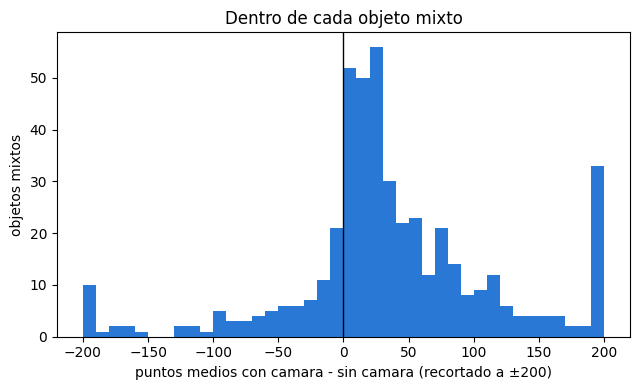

**Lectura (generada).** En 460 objetos mixtos, el 80,0 % tiene más puntos en los frames con par 2D que en los frames sin él (diferencia mediana de 25,7 puntos; Wilcoxon p = 1.9e-29). Los frames sin par 2D están además más lejos del auto en el 56,1 % de los objetos (diferencia mediana de distancia -0,81 m), así que parte del efecto puede venir de que el objeto se aleja o se acerca: el cambio de estado dentro de un mismo objeto **está asociado con el número de puntos**, pero no lo aísla de la distancia.

In [9]:
oo = bz.groupby([GRUPO, "key.laser_object_id", "sin"]).agg(n=("sin", "size"), pts=("num_lidar_points", "mean"), dist=("distancia_m", "mean")).unstack("sin")
ok = (oo[("n", 0)] >= 5) & (oo[("n", 1)] >= 5)
oo = oo[ok]
dif_pts = (oo[("pts", 0)] - oo[("pts", 1)]).values            # con camara menos sin camara
dif_dist = (oo[("dist", 0)] - oo[("dist", 1)]).values
frac_menos = float((dif_pts > 0).mean())
w = wilcoxon(dif_pts)
RES["pareado"] = {"objetos": int(len(oo)), "frac": frac_menos, "mediana": float(np.median(dif_pts)), "p": float(w.pvalue), "mediana_dist": float(np.median(dif_dist)), "frac_dist_mayor": float((dif_dist < 0).mean())}
print(f"Objetos mixtos con >= 5 frames por estado: {len(oo)} de {bz.groupby([GRUPO, 'key.laser_object_id']).ngroups}")
print(f"Diferencia de puntos medios (con camara - sin camara): mediana {np.median(dif_pts):.1f} | fraccion de objetos con mas puntos en los frames con camara: {frac_menos:.3f} | Wilcoxon p = {w.pvalue:.2e}")
print(f"Diferencia de distancia (con camara - sin camara): mediana {np.median(dif_dist):.2f} m | fraccion de objetos donde los frames sin camara estan mas lejos: {(dif_dist < 0).mean():.3f}")
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.hist(np.clip(dif_pts, -200, 200), bins=40, color=AZUL)
ax.axvline(0, color="k", lw=1)
ax.set_xlabel("puntos medios con camara - sin camara (recortado a ±200)"); ax.set_ylabel("objetos mixtos")
ax.set_title("Dentro de cada objeto mixto")
fig.tight_layout()
guardar_fig(fig, "08_pareado_objetos_mixtos")
plt.show()
r_ = RES["pareado"]
display(Markdown(
    f"**Lectura (generada).** En {r_['objetos']} objetos mixtos, el {pct(r_['frac'])} tiene más puntos en los frames con par 2D que en los frames sin él (diferencia mediana de {n2(r_['mediana'], 1)} puntos; Wilcoxon p = {r_['p']:.1e}). "
    f"Los frames sin par 2D están además más lejos del auto en el {pct(r_['frac_dist_mayor'])} de los objetos (diferencia mediana de distancia {n2(r_['mediana_dist'])} m), "
    f"así que parte del efecto puede venir de que el objeto se aleja o se acerca: el cambio de estado dentro de un mismo objeto " +
    ("**está asociado con el número de puntos**, pero no lo aísla de la distancia." if r_["frac"] > 0.5 and r_["p"] < 0.05 else "no se explica de forma clara por el número de puntos.")))

## A.5 Tasa de `sin_camara` según el azimut

`azimut_abs_deg` es la segunda variable en la importancia por permutación. Miramos la tasa por bins de 20 grados entre 0 y 120 (0 = frente del auto), con IC por segmentos y por clase cuando hay filas suficientes (≥ 200).
Es una descripción de la cobertura de etiquetado; **no sacamos conclusiones sobre física de cámara**.

Todos (peatones y ciclistas):
                filas   tasa     lo     hi
(-0.001, 20.0]  28873  0.233  0.156  0.294
(20.0, 40.0]    15977  0.180  0.141  0.218
(40.0, 60.0]     8765  0.172  0.108  0.245
(60.0, 80.0]     6043  0.210  0.141  0.265
(80.0, 100.0]    4851  0.206  0.141  0.292
(100.0, 120.0]   4046  0.622  0.550  0.677

Solo PEDESTRIAN (bins con menos de 200 filas quedan en NaN):
                filas   tasa     lo     hi
(-0.001, 20.0]  28067  0.238  0.162  0.298
(20.0, 40.0]    15575  0.182  0.144  0.220
(40.0, 60.0]     8675  0.170  0.106  0.243
(60.0, 80.0]     5901  0.212  0.143  0.270
(80.0, 100.0]    4808  0.207  0.142  0.294
(100.0, 120.0]   4013  0.621  0.549  0.679

Solo CYCLIST (bins con menos de 200 filas quedan en NaN):
                filas   tasa     lo     hi
(-0.001, 20.0]    806  0.041  0.000  0.099
(20.0, 40.0]      402  0.080  0.008  0.226
(40.0, 60.0]       90    NaN    NaN    NaN
(60.0, 80.0]      142    NaN    NaN    NaN
(80.0, 100.0]      43    NaN    

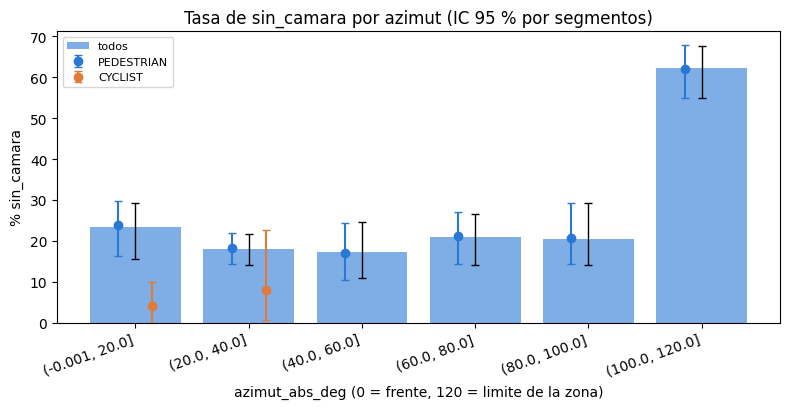

**Lectura (generada).** La tasa de `sin_camara` va de 17,2 % (bin (40.0, 60.0]) a 62,2 % (bin (100.0, 120.0]). El mayor salto entre bins contiguos es de +41.6 puntos, entre (80.0, 100.0] y (100.0, 120.0]. Regla descriptiva: hay un borde de mayor tasa si los IC de dos bins contiguos no se solapan. Hay 1 borde de ese tipo: entre (80.0, 100.0] y (100.0, 120.0] (+41.6 puntos). Los ciclistas tienen filas suficientes (≥ 200) en 2 de 6 bins, así que su curva es parcial. Esta es una descripción de la cobertura de etiquetado; no interpretamos su causa.

In [10]:
bz["az_bin"] = pd.cut(bz["azimut_abs_deg"], np.arange(0, 121, 20), include_lowest=True)
t_az, _ = tasa_ci(bz["az_bin"])
t_az_cl = {c: tasa_ci(bz["az_bin"].where(bz["object_type"] == c))[0] for c in VRU}
for c in VRU:
    t_az_cl[c].loc[t_az_cl[c]["filas"] < 200, ["tasa", "lo", "hi"]] = np.nan
print("Todos (peatones y ciclistas):")
print(t_az.round(3).to_string())
for c in VRU:
    print(f"\nSolo {c} (bins con menos de 200 filas quedan en NaN):")
    print(t_az_cl[c].round(3).to_string())
pd.concat({"todos": t_az, **t_az_cl}, names=["grupo"]).to_csv(RUTA_REPORTING / "08_tasa_por_azimut.csv")

fig, ax = plt.subplots(figsize=(8, 4.2))
x = np.arange(len(t_az))
ax.bar(x, t_az["tasa"] * 100, color=AZUL, alpha=0.6, label="todos")
ax.errorbar(x, t_az["tasa"] * 100, yerr=[(t_az["tasa"] - t_az["lo"]) * 100, (t_az["hi"] - t_az["tasa"]) * 100], fmt="none", color="k", capsize=3, lw=1)
for c, col, off in [("PEDESTRIAN", AZUL, -0.15), ("CYCLIST", NARANJA, 0.15)]:
    t = t_az_cl[c]
    ax.errorbar(x + off, t["tasa"] * 100, yerr=[(t["tasa"] - t["lo"]) * 100, (t["hi"] - t["tasa"]) * 100], fmt="o", color=col, capsize=3, label=c)
ax.set_xticks(x, [str(i) for i in t_az.index], rotation=20, ha="right"); ax.set_xlabel("azimut_abs_deg (0 = frente, 120 = limite de la zona)")
ax.set_ylabel("% sin_camara"); ax.set_title("Tasa de sin_camara por azimut (IC 95 % por segmentos)"); ax.legend(fontsize=8)
fig.tight_layout()
guardar_fig(fig, "08_tasa_por_azimut")
plt.show()

saltos = []
for i in range(len(t_az) - 1):
    solapan = bool(t_az["lo"].iloc[i + 1] <= t_az["hi"].iloc[i] and t_az["lo"].iloc[i] <= t_az["hi"].iloc[i + 1])
    saltos.append((t_az.index[i], t_az.index[i + 1], (t_az["tasa"].iloc[i + 1] - t_az["tasa"].iloc[i]) * 100, solapan))
mayor = max(saltos, key=lambda z: abs(z[2]))
sin_solape = [z for z in saltos if not z[3]]
cl_bins = int(t_az_cl["CYCLIST"]["tasa"].notna().sum())
RES["azimut"] = {"min": float(t_az["tasa"].min()), "max": float(t_az["tasa"].max()), "bordes": len(sin_solape)}
display(Markdown(
    f"**Lectura (generada).** La tasa de `sin_camara` va de {pct(t_az['tasa'].min())} (bin {t_az['tasa'].idxmin()}) a {pct(t_az['tasa'].max())} (bin {t_az['tasa'].idxmax()}). "
    f"El mayor salto entre bins contiguos es de {mayor[2]:+.1f} puntos, entre {mayor[0]} y {mayor[1]}. Regla descriptiva: hay un borde de mayor tasa si los IC de dos bins contiguos no se solapan. " +
    (f"Hay {len(sin_solape)} {'borde' if len(sin_solape) == 1 else 'bordes'} de ese tipo: " + "; ".join(f"entre {z[0]} y {z[1]} ({z[2]:+.1f} puntos)" for z in sin_solape) + "."
     if sin_solape else "No hay bordes de ese tipo: la tasa cambia de forma gradual con el azimut.") +
    f" Los ciclistas tienen filas suficientes (≥ 200) en {cl_bins} de {len(t_az)} bins, así que su curva es parcial. Esta es una descripción de la cobertura de etiquetado; no interpretamos su causa."))

## A.6 ¿Dónde empieza el salto entre 100 y 120 grados?

En A.5 la tasa de `sin_camara` pasa de 17,2 % a 62,2 % en el bin 100–120. Acá se mira con bins de 5 grados entre 80 y 120, y se reevalúan los modelos **excluyendo la franja 100–120** (lectura tomada: se evalúan las predicciones fuera de fold existentes solo en las filas con azimut ≤ 100).

**Campo de visión de las cámaras (documentación).** El [artículo del dataset](https://arxiv.org/abs/1912.04838) (Sun et al., 2020) lista, según el resumen obtenido en la búsqueda, un campo de visión horizontal de ±25,2° para cada una de las cinco cámaras (frontal, frontal izquierda y derecha, lateral izquierda y derecha).
**No pude verificar la orientación de montaje de cada cámara** (la tabla y la figura del PDF no se pudieron leer como texto), así que **no afirmamos qué rango de azimut cubren en conjunto**.

Tasa de sin_camara por bins de 5 grados entre 80 y 120:
            filas   tasa     lo     hi
(80, 85]     1114  0.236  0.158  0.352
(85, 90]     1400  0.247  0.130  0.361
(90, 95]     1376  0.162  0.087  0.274
(95, 100]     961  0.172  0.104  0.240
(100, 105]    874  0.260  0.156  0.332
(105, 110]   1015  0.370  0.262  0.467
(110, 115]   1024  0.762  0.639  0.873
(115, 120]   1133  1.000  1.000  1.000

Bandas (<=100 y 100-120):
                 filas   tasa     lo     hi
(-0.001, 100.0]  64509  0.207  0.167  0.245
(100.0, 120.0]    4046  0.622  0.550  0.677


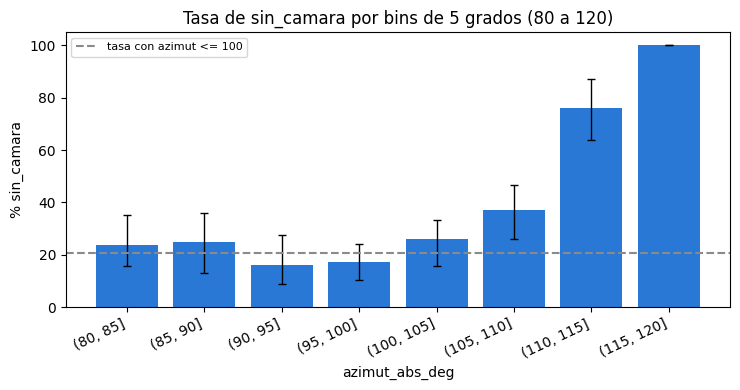

**Lectura (generada).** Con azimut ≤ 100 la tasa de `sin_camara` es 20,7 % y en 100–120, 62,2 %; la franja contiene el 5,9 % de las filas de B. Por bins de 5 grados, la tasa va de 23,6 % en (80, 85] a 100,0 % en (115, 120]. El primer bin cuyo IC queda por encima del IC de la banda ≤ 100 es (105, 110] (37,0 %): ahí empieza el salto.

In [11]:
az = bz["azimut_abs_deg"]
t5, _ = tasa_ci(pd.cut(az, np.arange(80, 121, 5)))
bandas, _ = tasa_ci(pd.cut(az, [-0.001, 100, 120]))
base_hi = bandas["hi"].iloc[0]
primero = next((i for i in t5.index if t5.loc[i, "lo"] > base_hi), None)
print("Tasa de sin_camara por bins de 5 grados entre 80 y 120:")
print(t5.round(3).to_string())
print("\nBandas (<=100 y 100-120):")
print(bandas.round(3).to_string())
t5.to_csv(RUTA_REPORTING / "08_tasa_azimut_5grados.csv")
fig, ax = plt.subplots(figsize=(7.5, 4))
x = np.arange(len(t5))
ax.bar(x, t5["tasa"] * 100, color=AZUL)
ax.errorbar(x, t5["tasa"] * 100, yerr=[(t5["tasa"] - t5["lo"]) * 100, (t5["hi"] - t5["tasa"]) * 100], fmt="none", color="k", capsize=3, lw=1)
ax.axhline(bandas["tasa"].iloc[0] * 100, color=GRIS, ls="--", label="tasa con azimut <= 100")
ax.set_xticks(x, [str(i) for i in t5.index], rotation=25, ha="right"); ax.set_xlabel("azimut_abs_deg"); ax.set_ylabel("% sin_camara")
ax.set_title("Tasa de sin_camara por bins de 5 grados (80 a 120)"); ax.legend(fontsize=8)
fig.tight_layout()
guardar_fig(fig, "08_tasa_azimut_5grados")
plt.show()
RES["a6"] = {"tasa_banda": float(bandas["tasa"].iloc[1]), "tasa_resto": float(bandas["tasa"].iloc[0]), "share_banda": float(bandas["filas"].iloc[1] / bandas["filas"].sum()), "primero": primero}
a_ = RES["a6"]
display(Markdown(
    f"**Lectura (generada).** Con azimut ≤ 100 la tasa de `sin_camara` es {pct(a_['tasa_resto'])} y en 100–120, {pct(a_['tasa_banda'])}; la franja contiene el {pct(a_['share_banda'])} de las filas de B. "
    f"Por bins de 5 grados, la tasa va de {pct(t5['tasa'].iloc[0])} en {t5.index[0]} a {pct(t5['tasa'].iloc[-1])} en {t5.index[-1]}. " +
    (f"El primer bin cuyo IC queda por encima del IC de la banda ≤ 100 es {primero} ({pct(t5.loc[primero, 'tasa'])}): ahí empieza el salto." if primero else "Ningún bin de 5 grados tiene un IC por encima del IC de la banda ≤ 100: el salto no se localiza con esta resolución.")))

In [12]:
def boot_sub(mask, scores, n_boot=N_BOOT, seed=SEMILLA):
    # Metricas con IC por bootstrap de segmentos en el subconjunto `mask` (mismas funciones y folds que arriba). Devuelve puntos y arreglos remuestreados.
    ii0 = np.where(mask)[0]
    y_, tb_ = yB[ii0], tb_f[ii0]
    segs = [a for a in (np.where(seg_codes[ii0] == s)[0] for s in range(S_N)) if len(a)]
    rng = np.random.default_rng(seed)
    punto = {n: metricas_score(y_, sc[ii0], tb_) for n, sc in scores.items()}
    boot = {n: {m: [] for m in punto[n]} for n in scores}
    for _ in range(n_boot):
        ii = np.concatenate([segs[j] for j in rng.integers(0, len(segs), len(segs))])
        if len(np.unique(y_[ii])) < 2:
            continue
        for n, sc in scores.items():
            r = metricas_score(y_[ii], sc[ii0][ii], tb_[ii])
            for m, v in r.items():
                boot[n][m].append(v)
    return punto, {n: {m: np.array(v) for m, v in d.items()} for n, d in boot.items()}, int(mask.sum()), len(segs)


scores_a6 = {"HGB": s_hgb, "Regresion logistica": s_lr, REGLA: s_regla}
poblaciones = {"B completa": np.ones(len(bz), bool), "sin la franja 100-120": (bz["azimut_abs_deg"] <= 100).values}
res_pob = {n: boot_sub(m, scores_a6) for n, m in poblaciones.items()}
filas = []
for pn, (pt, bt, nfil, nseg) in res_pob.items():
    for mn in scores_a6:
        fila = {"poblacion": pn, "filas": nfil, "metodo": mn}
        for met in ["AUC", "PR-AUC", "Captura@20%", "Fraccion para 80%"]:
            lo, hi = np.percentile(bt[mn][met], [2.5, 97.5])
            fila[met] = f"{pt[mn][met]:.3f} ({lo:.3f} a {hi:.3f})"
        filas.append(fila)
comp6 = pd.DataFrame(filas)
dif = {}
for pn, (pt, bt, nfil, nseg) in res_pob.items():
    for met in ["AUC", "Fraccion para 80%", "Captura@20%"]:
        d = bt["HGB"][met] - bt[REGLA][met]
        dif[(pn, met)] = (pt["HGB"][met] - pt[REGLA][met], *np.percentile(d, [2.5, 97.5]))
print(comp6.to_string(index=False))
print("\nDiferencia HGB - regla simple (valor, IC95% pareado):", {k: tuple(round(float(x), 3) for x in v) for k, v in dif.items()})
comp6.to_csv(RUTA_REPORTING / "08_comparacion_sin_franja.csv", index=False)
RES["a6"]["dif"] = dif
RES["a6"]["f80_full"], RES["a6"]["f80_excl"] = res_pob["B completa"][0]["HGB"]["Fraccion para 80%"], res_pob["sin la franja 100-120"][0]["HGB"]["Fraccion para 80%"]
d_full, d_ex = dif[("B completa", "Fraccion para 80%")], dif[("sin la franja 100-120", "Fraccion para 80%")]
auc_ex = dif[("sin la franja 100-120", "AUC")]
display(Markdown(
    f"**Lectura (generada).** En B completa, el HGB menos la regla simple da {d_full[0] * 100:+.1f} puntos en Fracción para 80 % (IC 95 % {d_full[1] * 100:+.1f} a {d_full[2] * 100:+.1f}). "
    f"Excluyendo la franja 100–120 ({miles(res_pob['sin la franja 100-120'][2])} filas de {miles(len(bz))}), la diferencia es {d_ex[0] * 100:+.1f} puntos (IC {d_ex[1] * 100:+.1f} a {d_ex[2] * 100:+.1f}) y el AUC del HGB menos el de la regla es {auc_ex[0]:+.3f} (IC {auc_ex[1]:+.3f} a {auc_ex[2]:+.3f}). "
    f"**La ventaja sobre la regla " + ("se mantiene" if d_ex[2] < 0 else "deja de ser distinguible") + "** (" + ("el IC sigue excluyendo 0" if d_ex[2] < 0 else "el IC incluye 0") + ") y " +
    ("es " + ("menor" if abs(d_ex[0]) < abs(d_full[0]) else "mayor o igual") + " que en B completa.")))

            poblacion  filas                            metodo                   AUC                PR-AUC           Captura@20%     Fraccion para 80%
           B completa  68555                               HGB 0.854 (0.810 a 0.897) 0.747 (0.672 a 0.813) 0.613 (0.542 a 0.702) 0.391 (0.292 a 0.478)
           B completa  68555               Regresion logistica 0.838 (0.792 a 0.899) 0.695 (0.600 a 0.785) 0.585 (0.507 a 0.692) 0.411 (0.286 a 0.516)
           B completa  68555 Regla: menos puntos LiDAR primero 0.797 (0.748 a 0.847) 0.661 (0.555 a 0.735) 0.579 (0.507 a 0.665) 0.505 (0.405 a 0.607)
sin la franja 100-120  64509                               HGB 0.835 (0.782 a 0.882) 0.682 (0.580 a 0.768) 0.602 (0.525 a 0.700) 0.409 (0.302 a 0.504)
sin la franja 100-120  64509               Regresion logistica 0.838 (0.789 a 0.902) 0.683 (0.581 a 0.788) 0.621 (0.538 a 0.737) 0.405 (0.262 a 0.524)
sin la franja 100-120  64509 Regla: menos puntos LiDAR primero 0.858 (0.810 a 0.901) 0.698 (0.

**Lectura (generada).** En B completa, el HGB menos la regla simple da -11.4 puntos en Fracción para 80 % (IC 95 % -20.4 a -5.1). Excluyendo la franja 100–120 (64.509 filas de 68.555), la diferencia es +2.4 puntos (IC -3.9 a +7.5) y el AUC del HGB menos el de la regla es -0.023 (IC -0.041 a -0.005). **La ventaja sobre la regla deja de ser distinguible** (el IC incluye 0) y es menor que en B completa.

## A.7 Geometría de las cámaras: verificación

**Por qué importa.** La tasa de `sin_camara` llega a 100 % en 115–120° (A.6). Si es geometría de los sensores y no una laguna de etiquetado, conviene medirla donde está la fuente: la calibración de las cámaras. Se busca el componente `camera_calibration`; si no está, se dice y se usa lo que sí hay.

In [13]:
raiz_waymo = RAIZ / "data" / "01_raw" / "waymo"
calib_files = [f_ for f_ in raiz_waymo.rglob("*.parquet") if "calibration" in f_.parent.name.lower() or "calibration" in f_.name.lower()]
hay_calib = len(calib_files) > 0
print("Componentes en data/01_raw/waymo:", sorted(p_.name for p_ in raiz_waymo.iterdir()))
print(f"camera_calibration encontrado: {hay_calib}")
RES["a7"] = {"hay_calib": bool(hay_calib)}
if hay_calib:
    # Rama con calibracion (no se ejecuta en esta corrida: el componente no esta en los datos locales). Convencion de Waymo: eje x de la camara = eje optico,
    # extrinseca = camera-to-vehicle (4x4 por filas), intrinseca = [f_u, f_v, c_u, c_v, k1, k2, p1, p2, k3].
    arch = sorted(calib_files)[0]
    cal = pd.read_parquet(arch)
    ext_c = [c_ for c_ in cal.columns if "extrinsic" in c_ and "transform" in c_][0]
    int_c = [c_ for c_ in cal.columns if c_.endswith(".intrinsic")][0]
    w_c = [c_ for c_ in cal.columns if c_.endswith(".width")][0]
    filas = []
    for _, r_ in cal.iterrows():
        T_ = np.asarray(r_[ext_c], dtype=float).reshape(4, 4)
        yaw = np.degrees(np.arctan2(T_[1, 0], T_[0, 0]))
        fov = np.degrees(2 * np.arctan(r_[w_c] / (2 * np.asarray(r_[int_c], dtype=float)[0])))
        filas.append({"camara": r_["key.camera_name"], "yaw (grados)": yaw, "campo de vision horizontal (grados)": fov, "azimut desde": yaw - fov / 2, "azimut hasta": yaw + fov / 2})
    tabla_cal = pd.DataFrame(filas)
    print(tabla_cal.round(1).to_string(index=False))
    tabla_cal.to_csv(RUTA_REPORTING / "08_geometria_camaras.csv", index=False)
    RES["a7"]["union"] = (float(tabla_cal["azimut desde"].min()), float(tabla_cal["azimut hasta"].max()))
else:
    print("No se calcula yaw ni campo de vision: sin calibracion no se inventan valores.")
    print("Componente a descargar de un segmento (es pequeno): camera_calibration -> gs://waymo_open_dataset_v_2_0_1/training/camera_calibration/<segmento>.parquet")

Componentes en data/01_raw/waymo: ['camera_to_lidar_box_association', 'lidar_box', 'metadatos_ep2', 'vehicle_pose']
camera_calibration encontrado: False
No se calcula yaw ni campo de vision: sin calibracion no se inventan valores.
Componente a descargar de un segmento (es pequeno): camera_calibration -> gs://waymo_open_dataset_v_2_0_1/training/camera_calibration/<segmento>.parquet


**Complemento empírico (no es calibración).** La tabla de asociación cámara-LiDAR trae `key.camera_name`. Con ella se mira, por cámara, el azimut con signo (0 = frente, positivo a la izquierda) de las cajas 3D que tienen par 2D en esa cámara, solo en segmentos de train.
La numeración de cámaras sigue la del proto de Waymo (1 frontal, 2 frontal izquierda, 3 frontal derecha, 4 lateral izquierda, 5 lateral derecha); **no la verifiqué contra la documentación**.

Asociaciones (segmentos de train): 57,861
          camara  asociaciones  azimut p1     p5  mediana   p95   p99    min   max
     1 (frontal)         25020      -23.3  -21.0     -6.5  20.1  23.2  -25.2  26.3
2 (frontal izq.)         11926       18.9   20.4     36.1  63.1  66.8   16.0  69.5
3 (frontal der.)         10929      -63.6  -60.5    -32.8 -19.5 -17.1  -69.0 -10.4
4 (lateral izq.)          6359       60.8   64.4     85.2 109.2 111.6   45.1 113.7
5 (lateral der.)          3627     -109.5 -105.3    -77.3 -57.6 -52.4 -113.2 -43.3


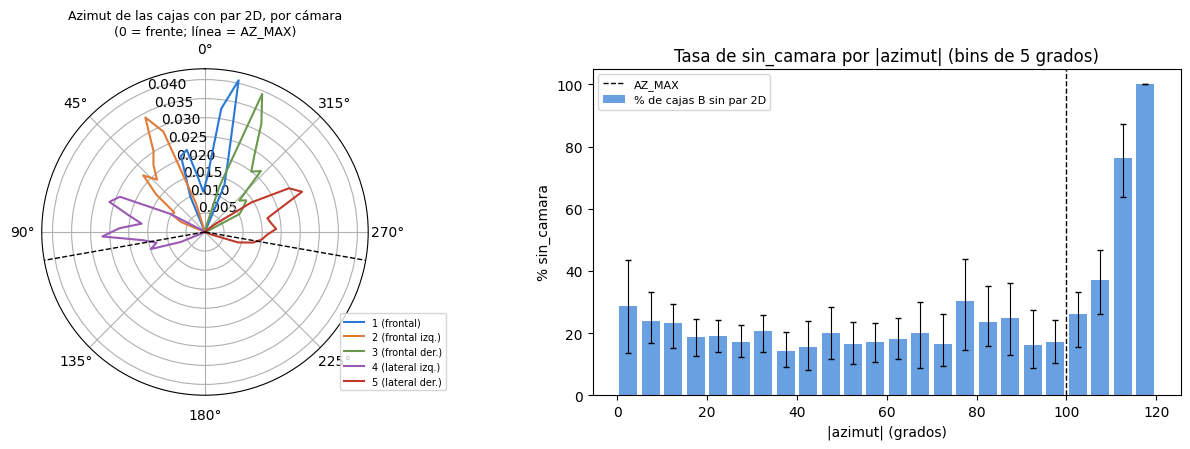

**Lectura (generada).** **El componente `camera_calibration` no existe en los datos locales**, así que no se calculan ni el yaw ni el campo de visión de cada cámara y no se inventan valores (componente a descargar: `camera_calibration` de un segmento). Complemento empírico (no es calibración): de las 57.861 cajas con par 2D en segmentos de train, el 99 % tiene |azimut| ≤ 107,6° y el 99,5 %, ≤ 109,6°; el 2,6 % está más allá de AZ_MAX = 100° y el 0,0 % más allá de 120°. La tasa de `sin_camara` entre las cajas de B pasa de 20,7 % con |azimut| ≤ 100° a 62,2 % entre 100° y 120°. Con este criterio empírico, el borde de la cobertura (percentil 99 de |azimut| de las cajas con par 2D) está en 107,6°, por encima de AZ_MAX = 100° (7,6° de diferencia). AZ_MAX es entonces **conservador**: deja fuera la franja entre 100° y ese borde, donde todavía hay cajas con par 2D (el 2,6 % de las asociaciones). Sin la calibración no se puede afirmar el borde geométrico exacto. AZ_MAX no se cambia en esta pasada.

In [14]:
asoc_dir = RAIZ / "data" / "01_raw" / "waymo" / "camera_to_lidar_box_association"
archivos = [f_ for f_ in sorted(asoc_dir.glob("*.parquet")) if f_.stem in SEGS_TRAIN]
assert archivos and all(f_.stem not in SEGS_TEST for f_ in archivos)
asoc = pd.concat([pd.read_parquet(f_, columns=["key.segment_context_name", "key.frame_timestamp_micros", "key.camera_name", "key.laser_object_id"]) for f_ in archivos], ignore_index=True)
asoc = asoc.rename(columns={"key.segment_context_name": GRUPO})
cajas = completo[[GRUPO, "key.frame_timestamp_micros", "key.laser_object_id", "box_center_x", "box_center_y"]]
asoc = asoc.merge(cajas, on=[GRUPO, "key.frame_timestamp_micros", "key.laser_object_id"], how="inner")
asoc["az"] = np.degrees(np.arctan2(asoc["box_center_y"], asoc["box_center_x"]))
NOMBRE_CAM = {1: "1 (frontal)", 2: "2 (frontal izq.)", 3: "3 (frontal der.)", 4: "4 (lateral izq.)", 5: "5 (lateral der.)"}
filas = []
for cam, g in asoc.groupby("key.camera_name"):
    q = g["az"].quantile([0.01, 0.05, 0.5, 0.95, 0.99])
    filas.append({"camara": NOMBRE_CAM.get(cam, str(cam)), "asociaciones": len(g), "azimut p1": q[0.01], "p5": q[0.05], "mediana": q[0.5], "p95": q[0.95], "p99": q[0.99], "min": g["az"].min(), "max": g["az"].max()})
tabla_cam = pd.DataFrame(filas)
print(f"Asociaciones (segmentos de train): {len(asoc):,}")
print(tabla_cam.round(1).to_string(index=False))
tabla_cam.to_csv(RUTA_REPORTING / "08_azimut_por_camara_empirico.csv", index=False)
abs_az = asoc["az"].abs()
p99_union, p995_union = float(abs_az.quantile(0.99)), float(abs_az.quantile(0.995))
frac_fuera = float((abs_az > AZ_MAX).mean())
frac_fuera_120 = float((abs_az > ZONA_CAMARAS_DEG).mean())
# fraccion de cajas B sin par 2D por |azimut| en bins de 5 grados (toda B, 0 a 120)
bins5 = np.arange(0, 121, 5)
tb5, _ = tasa_ci(pd.cut(bz["azimut_abs_deg"], bins5, include_lowest=True))
asoc_bin = pd.cut(abs_az, bins5, include_lowest=True).value_counts(normalize=True).sort_index()
RES["a7"].update({"p99": p99_union, "p995": p995_union, "frac_fuera_az_max": frac_fuera, "frac_fuera_120": frac_fuera_120})

fig = plt.figure(figsize=(13, 4.6))
ax = fig.add_subplot(1, 2, 1, projection="polar")
ax.set_theta_zero_location("N"); ax.set_theta_direction(1)
for (cam, g), col in zip(asoc.groupby("key.camera_name"), [AZUL, NARANJA, VERDE, "#9b59b6", "#c0392b"]):
    h, e = np.histogram(g["az"], bins=np.arange(-180, 181, 5), density=True)
    ax.plot(np.radians((e[:-1] + e[1:]) / 2), h, color=col, label=NOMBRE_CAM.get(cam, str(cam)))
ax.axvline(np.radians(AZ_MAX), color="k", ls="--", lw=1); ax.axvline(np.radians(-AZ_MAX), color="k", ls="--", lw=1)
ax.set_title("Azimut de las cajas con par 2D, por cámara\n(0 = frente; línea = AZ_MAX)", fontsize=9); ax.legend(fontsize=7, loc="lower left", bbox_to_anchor=(0.9, 0))
ax2 = fig.add_subplot(1, 2, 2)
x_ = (bins5[:-1] + bins5[1:]) / 2
ax2.bar(x_, tb5["tasa"] * 100, width=4, color=AZUL, alpha=0.7, label="% de cajas B sin par 2D")
ax2.errorbar(x_, tb5["tasa"] * 100, yerr=[(tb5["tasa"] - tb5["lo"]) * 100, (tb5["hi"] - tb5["tasa"]) * 100], fmt="none", color="k", capsize=2, lw=0.8)
ax2.axvline(AZ_MAX, color="k", ls="--", lw=1, label="AZ_MAX")
ax2.set_xlabel("|azimut| (grados)"); ax2.set_ylabel("% sin_camara"); ax2.set_title("Tasa de sin_camara por |azimut| (bins de 5 grados)"); ax2.legend(fontsize=8)
fig.tight_layout()
guardar_fig(fig, "08_geometria_camaras")
plt.show()
r7 = RES["a7"]
display(Markdown(
    f"**Lectura (generada).** " + ("Con la calibración, la unión de las cinco cámaras cubre de " + f"{n2(r7['union'][0], 1)}° a {n2(r7['union'][1], 1)}° de azimut. " if r7["hay_calib"] else
     "**El componente `camera_calibration` no existe en los datos locales**, así que no se calculan ni el yaw ni el campo de visión de cada cámara y no se inventan valores (componente a descargar: `camera_calibration` de un segmento). ") +
    f"Complemento empírico (no es calibración): de las {miles(len(asoc))} cajas con par 2D en segmentos de train, el 99 % tiene |azimut| ≤ {n2(p99_union, 1)}° y el 99,5 %, ≤ {n2(p995_union, 1)}°; el {pct(frac_fuera)} está más allá de AZ_MAX = {AZ_MAX}° y el {pct(frac_fuera_120)} más allá de {ZONA_CAMARAS_DEG}°. "
    f"La tasa de `sin_camara` entre las cajas de B pasa de {pct(float(bz.loc[bz['azimut_abs_deg'] <= AZ_MAX, 'sin'].mean()))} con |azimut| ≤ {AZ_MAX}° a {pct(float(bz.loc[bz['azimut_abs_deg'] > AZ_MAX, 'sin'].mean()))} entre {AZ_MAX}° y {ZONA_CAMARAS_DEG}°. "
    f"Con este criterio empírico, el borde de la cobertura (percentil 99 de |azimut| de las cajas con par 2D) está en {n2(p99_union, 1)}°, " + ("por debajo de" if p99_union <= AZ_MAX else "por encima de") + f" AZ_MAX = {AZ_MAX}° ({n2(abs(p99_union - AZ_MAX), 1)}° de diferencia). " +
    (f"AZ_MAX es entonces **conservador**: deja fuera la franja entre {AZ_MAX}° y ese borde, donde todavía hay cajas con par 2D (el {pct(frac_fuera)} de las asociaciones). " if p99_union > AZ_MAX else f"AZ_MAX queda dentro del borde empírico de la cobertura. ") +
    "Sin la calibración no se puede afirmar el borde geométrico exacto. AZ_MAX no se cambia en esta pasada."))

# B. Robustez: AUC por segmento

**Por qué importa.** El AUC agrupado mezcla segmentos con niveles de etiquetado muy distintos (la tasa de `sin_camara` va de 1,5 % a 33,6 % entre segmentos del test). Si el modelo solo aprendiera "este segmento etiqueta poco",
el AUC agrupado se inflaría. El AUC dentro de cada segmento no tiene ese problema.

Segmentos evaluables (>= 200 filas por clase): 16 de 33
                                   mediana     Q1     Q3    min    max  AUC agrupado
HGB                                  0.864  0.818  0.913  0.626  0.971         0.854
Regresion logistica                  0.873  0.802  0.920  0.639  0.968         0.838
Regla: menos puntos LiDAR primero    0.802  0.743  0.866  0.408  0.951         0.797


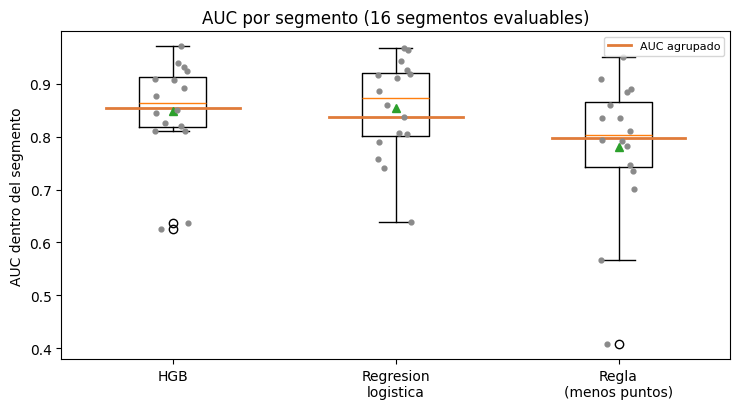

**Lectura (generada).** Con 16 segmentos evaluables (≥ 200 filas por clase), la mediana del AUC por segmento del HGB es 0,864 (rango intercuartil 0,818–0,913), de la regresión logística 0,873 y de la regla simple 0,802. El AUC agrupado del HGB es 0,854: no supera a la mediana por segmento (-0,010), así que el AUC agrupado no parece inflado por diferencias entre segmentos.

In [15]:
crit_s = CRIT["auc_segmento"]
filas_seg = []
for si, s in enumerate(seg_nombres):
    ii = idx_seg[si]
    n1, n0 = int(yB[ii].sum()), int((1 - yB[ii]).sum())
    filas_seg.append({"segmento": s, "filas": len(ii), "sin": n1, "con": n0, "prev": n1 / len(ii),
                      **{n: (roc_auc_score(yB[ii], sc[ii]) if min(n1, n0) > 1 else np.nan) for n, sc in [("HGB", s_hgb), ("Regresion logistica", s_lr), (REGLA, s_regla)]}})
seg_df = pd.DataFrame(filas_seg)
minimo = crit_s["min_filas_clase"]
evaluables = seg_df[(seg_df["sin"] >= minimo) & (seg_df["con"] >= minimo)]
if len(evaluables) < crit_s["min_segmentos"]:
    minimo = crit_s["min_filas_clase_relajado"]
    evaluables = seg_df[(seg_df["sin"] >= minimo) & (seg_df["con"] >= minimo)]
print(f"Segmentos evaluables (>= {minimo} filas por clase): {len(evaluables)} de {len(seg_df)}")
res_seg = pd.DataFrame({n: {"mediana": evaluables[n].median(), "Q1": evaluables[n].quantile(0.25), "Q3": evaluables[n].quantile(0.75), "min": evaluables[n].min(), "max": evaluables[n].max(),
                            "AUC agrupado": auc_base[n]} for n in ["HGB", "Regresion logistica", REGLA]}).T
print(res_seg.round(3).to_string())
seg_df.to_csv(RUTA_REPORTING / "08_auc_por_segmento.csv", index=False)

fig, ax = plt.subplots(figsize=(7.5, 4.2))
datos = [evaluables[n].dropna().values for n in ["HGB", "Regresion logistica", REGLA]]
ax.boxplot(datos, tick_labels=["HGB", "Regresion\nlogistica", "Regla\n(menos puntos)"], showmeans=True)
for i, n in enumerate(["HGB", "Regresion logistica", REGLA]):
    ax.scatter(np.full(len(datos[i]), i + 1) + np.random.default_rng(0).uniform(-0.08, 0.08, len(datos[i])), datos[i], s=12, color=GRIS, zorder=3)
    ax.plot([i + 0.7, i + 1.3], [auc_base[n]] * 2, color=NARANJA, lw=2, label="AUC agrupado" if i == 0 else None)
ax.set_ylabel("AUC dentro del segmento"); ax.set_title(f"AUC por segmento ({len(evaluables)} segmentos evaluables)"); ax.legend(fontsize=8)
fig.tight_layout()
guardar_fig(fig, "08_auc_por_segmento")
plt.show()

med_h, agr_h = res_seg.loc["HGB", "mediana"], auc_base["HGB"]
RES["segmento"] = {"n": len(evaluables), "minimo": minimo, "mediana": res_seg["mediana"].to_dict(), "q1": res_seg["Q1"].to_dict(), "q3": res_seg["Q3"].to_dict(), "agrupado": auc_base}
display(Markdown(
    f"**Lectura (generada).** Con {len(evaluables)} segmentos evaluables (≥ {minimo} filas por clase), la mediana del AUC por segmento del HGB es {n2(med_h, 3)} "
    f"(rango intercuartil {n2(res_seg.loc['HGB', 'Q1'], 3)}–{n2(res_seg.loc['HGB', 'Q3'], 3)}), de la regresión logística {n2(res_seg.loc['Regresion logistica', 'mediana'], 3)} y de la regla simple {n2(res_seg.loc[REGLA, 'mediana'], 3)}. "
    f"El AUC agrupado del HGB es {n2(agr_h, 3)}: " +
    (f"supera a la mediana por segmento en {n2(agr_h - med_h, 3)}, una diferencia compatible con que las diferencias de nivel de etiquetado entre segmentos aporten al AUC agrupado (hipótesis, no medida aparte)."
     if agr_h > med_h else f"no supera a la mediana por segmento ({n2(agr_h - med_h, 3)}), así que el AUC agrupado no parece inflado por diferencias entre segmentos.")))

# C. Variables nuevas solo con LiDAR (causales)

**Por qué importa.** La regla "menos puntos LiDAR primero" ya recoge buena parte de la señal. Para que el modelo valga la pena frente a ella, tiene que usar algo que la regla no tiene.
Probamos dos familias de variables que se pueden calcular **solo con cajas 3D del mismo track en frames anteriores o del mismo frame**; nunca con etiquetas de cámara.

- **Temporales** (solo frames ≤ t del mismo track): puntos en t−1 y t−2, media y mínimo de puntos en los últimos 5 y 10 frames, cambio de puntos respecto de t−1 y edad del track.
- **Oclusión** (solo cajas del mismo frame): intervalo angular que ocupa la caja vista desde el auto (4 esquinas de la caja orientada); un oclusor es cualquier caja del mismo frame, de cualquier clase, **más cercana al auto** (distancia del centro) cuyo intervalo angular se solape con el del objeto.
  Variables: número de oclusores, fracción del ancho angular cubierta por oclusores (suma de solapes, con cota a 1) y distancia (euclidiana entre centros) al oclusor más cercano.
  **Aproximación:** ignora la altura de las cajas y la transparencia de señales, y la suma de solapes puede contar dos veces zonas cubiertas por dos oclusores (la cota a 1 la acota).

## C.1 Construcción de las variables

In [16]:
# ---- Temporales: solo frames <= t del mismo (segmento, objeto)
base_pts = completo[[GRUPO, "key.laser_object_id", "fi", "num_lidar_points"]]
assert not base_pts.duplicated([GRUPO, "key.laser_object_id", "fi"]).any()
pos_pts = base_pts.set_index([GRUPO, "key.laser_object_id", "fi"])["num_lidar_points"]
M = np.column_stack([pos_pts.reindex(pd.MultiIndex.from_arrays([bz[GRUPO], bz["key.laser_object_id"], bz["fi"] - L])).values for L in range(10)])   # columna L = puntos en t-L
assert np.allclose(M[:, 0], bz["num_lidar_points"].values), "t no coincide con los puntos de la fila"
primero = completo.groupby([GRUPO, "key.laser_object_id"])["fi"].min()
bz["pts_t1"], bz["pts_t2"] = M[:, 1], M[:, 2]
bz["pts_media5"], bz["pts_min5"] = np.nanmean(M[:, :5], axis=1), np.nanmin(M[:, :5], axis=1)
bz["pts_media10"], bz["pts_min10"] = np.nanmean(M, axis=1), np.nanmin(M, axis=1)
bz["pts_delta1"] = M[:, 0] - M[:, 1]
bz["edad_track"] = bz["fi"].values - primero.reindex(pd.MultiIndex.from_arrays([bz[GRUPO], bz["key.laser_object_id"]])).values
TEMP = ["pts_t1", "pts_t2", "pts_media5", "pts_min5", "pts_media10", "pts_min10", "pts_delta1", "edad_track"]
print(bz[TEMP].describe().round(2).T[["count", "mean", "min", "max"]].to_string())
print(f"Filas sin t-1: {bz['pts_t1'].isna().mean():.1%} | sin t-2: {bz['pts_t2'].isna().mean():.1%} (HGB las maneja como faltantes)")

               count    mean     min     max
pts_t1       67860.0  101.00     0.0  7097.0
pts_t2       67163.0   99.70     0.0  7097.0
pts_media5   68555.0   98.90     0.0  6000.4
pts_min5     68555.0   85.87     0.0  4544.0
pts_media10  68555.0   95.01     0.0  4008.5
pts_min10    68555.0   72.56     0.0  1678.0
pts_delta1   67860.0    1.55 -1323.0  2106.0
edad_track   68555.0   67.18     0.0   198.0
Filas sin t-1: 1.0% | sin t-2: 2.0% (HGB las maneja como faltantes)


In [17]:
# ---- Oclusion: solo cajas del mismo frame
def wrap(a):
    return (a + np.pi) % (2 * np.pi) - np.pi


comp = completo[[GRUPO, "fi", "key.laser_object_id", "box_center_x", "box_center_y", "box_length", "box_width", "_h"]].merge(
    bz[[GRUPO, "fi", "key.laser_object_id"]].assign(_pos=np.arange(len(bz)).astype(float)), on=[GRUPO, "fi", "key.laser_object_id"], how="left")
n_ocl, frac_cub, dist_ocl = np.zeros(len(bz)), np.zeros(len(bz)), np.full(len(bz), np.nan)
t0 = time.time()
for (seg, fi), g in comp.groupby([GRUPO, "fi"], sort=False):
    pos = g["_pos"].values
    tgt = np.where(~np.isnan(pos))[0]
    if len(tgt) == 0:
        continue
    cx, cy, L, W, H = (g[c].values for c in ["box_center_x", "box_center_y", "box_length", "box_width", "_h"])
    c_, s_ = np.cos(H), np.sin(H)
    lx, ly = np.array([1, 1, -1, -1]) * (L[:, None] / 2), np.array([1, -1, 1, -1]) * (W[:, None] / 2)
    X, Y = cx[:, None] + lx * c_[:, None] - ly * s_[:, None], cy[:, None] + lx * s_[:, None] + ly * c_[:, None]
    th = np.arctan2(cy, cx)
    dl = wrap(np.arctan2(Y, X) - th[:, None])
    lo, hi = dl.min(1), dl.max(1)                      # intervalo angular de cada caja, relativo a su azimut central
    r = np.hypot(cx, cy)
    d = wrap(th[None, :] - th[tgt][:, None])           # azimut de cada caja j relativo al objetivo i
    ov = np.clip(np.minimum(hi[tgt][:, None], d + hi[None, :]) - np.maximum(lo[tgt][:, None], d + lo[None, :]), 0, None)
    occ = (r[None, :] < r[tgt][:, None]) & (ov > 0)
    occ[np.arange(len(tgt)), tgt] = False
    ancho = np.maximum(hi[tgt] - lo[tgt], 1e-6)
    p = pos[tgt].astype(int)
    n_ocl[p] = occ.sum(1)
    frac_cub[p] = np.minimum(1.0, (ov * occ).sum(1) / ancho)
    dd = np.where(occ, np.hypot(cx[None, :] - cx[tgt][:, None], cy[None, :] - cy[tgt][:, None]), np.inf).min(1)
    dist_ocl[p] = np.where(np.isinf(dd), np.nan, dd)
bz["n_ocl"], bz["frac_cub"], bz["dist_ocl"] = n_ocl, frac_cub, dist_ocl
OCL = ["n_ocl", "frac_cub", "dist_ocl"]
print(f"Oclusion calculada en {time.time() - t0:.0f} s")
print(bz[OCL].describe().round(3).T.to_string())
print(f"Cajas con al menos un oclusor: {(bz['n_ocl'] > 0).mean():.1%} | con fraccion cubierta > 0.5: {(bz['frac_cub'] > 0.5).mean():.1%}")

# Anti-fuga: ninguna variable nueva usa la camara, asociaciones ni etiquetas de otros frames u objetos
USADAS = ["num_lidar_points", "box_center_x", "box_center_y", "box_length", "box_width", "_h", "fi", "key.laser_object_id", GRUPO]
prohibidas = ("camara", "camera", "asoc", "tiene_", "sin_camara", "frame_etiquetado", "weather", "location", "time_of_day")
assert not [c for c in USADAS + TEMP + OCL if any(p in c.lower() for p in prohibidas)], "Variable sospechosa de fuga"
assert TARGET not in TEMP + OCL + TODAS_B and "sin" not in TEMP + OCL + TODAS_B
print("Control anti-fuga OK: las variables nuevas usan solo puntos LiDAR del mismo track (frames <= t) y geometria de cajas del mismo frame.")

Oclusion calculada en 5 s
            count   mean    std    min    25%   50%    75%     max
n_ocl     68555.0  1.834  1.703  0.000  1.000  1.00  3.000  12.000
frac_cub  68555.0  0.659  0.430  0.000  0.117  1.00  1.000   1.000
dist_ocl  52653.0  7.418  9.934  0.067  0.900  3.28  9.909  71.188
Cajas con al menos un oclusor: 76.8% | con fraccion cubierta > 0.5: 65.8%
Control anti-fuga OK: las variables nuevas usan solo puntos LiDAR del mismo track (frames <= t) y geometria de cajas del mismo frame.


## C.2 Evaluación de los cuatro conjuntos

`TODAS_B`, `TODAS_B + temporales`, `TODAS_B + oclusión` y `TODAS_B + ambos`; mismo HGB y mismos folds. IC 95 % por bootstrap de segmentos; las diferencias contra `TODAS_B` son pareadas.

                                        AUC PR-AUC            Captura@20%      Fraccion para 80%           dAUC vs TODAS_B dFraccion80 vs TODAS_B ayuda (criterio)
conjunto                                                                                                                                                          
TODAS_B               0.854 (0.810 a 0.897)  0.747  0.613 (0.542 a 0.702)  0.391 (0.292 a 0.478)                         -                      -                -
TODAS_B + temporales  0.852 (0.805 a 0.901)  0.749  0.616 (0.539 a 0.714)  0.400 (0.295 a 0.491)  -0.002 (-0.014 a +0.007)  +0.9 pp (-1.8 a +5.3)               no
TODAS_B + oclusion    0.853 (0.807 a 0.897)  0.746  0.611 (0.537 a 0.710)  0.388 (0.288 a 0.475)  -0.001 (-0.009 a +0.006)  -0.4 pp (-1.9 a +1.5)               no
TODAS_B + ambos       0.861 (0.816 a 0.907)  0.757  0.617 (0.540 a 0.717)  0.373 (0.271 a 0.447)  +0.007 (-0.002 a +0.015)  -1.8 pp (-4.3 a +1.5)               no


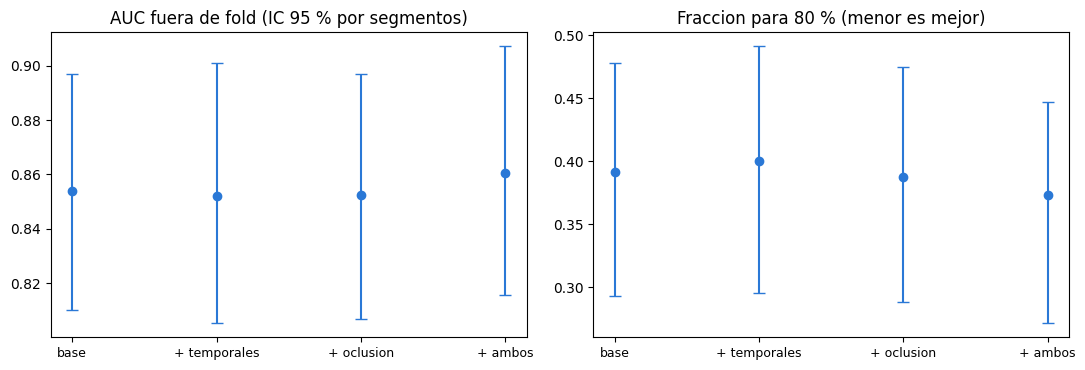

In [18]:
conjuntos = {"TODAS_B": TODAS_B, "TODAS_B + temporales": TODAS_B + TEMP, "TODAS_B + oclusion": TODAS_B + OCL, "TODAS_B + ambos": TODAS_B + TEMP + OCL}
scores_c = {n: (s_hgb if n == "TODAS_B" else oof_clasificador(bz[cols].values, yB, fB)) for n, cols in conjuntos.items()}
res_c = evaluar_boot(scores_c, ref="TODAS_B")
cr = CRIT["variable_nueva"]
res_c["ayuda"] = [bool(n != "TODAS_B" and r["dAUC"] >= cr["delta_auc_min"] and r["dAUC lo"] > 0 and r["dFraccion para 80%"] <= cr["delta_fraccion80_max"] and r["dFraccion para 80% hi"] < 0)
                  for n, r in res_c.iterrows()]
vista = pd.DataFrame({"AUC": [f"{r['AUC']:.3f} ({r['AUC lo']:.3f} a {r['AUC hi']:.3f})" for _, r in res_c.iterrows()],
                      "PR-AUC": [f"{r['PR-AUC']:.3f}" for _, r in res_c.iterrows()],
                      "Captura@20%": [f"{r['Captura@20%']:.3f} ({r['Captura@20% lo']:.3f} a {r['Captura@20% hi']:.3f})" for _, r in res_c.iterrows()],
                      "Fraccion para 80%": [f"{r['Fraccion para 80%']:.3f} ({r['Fraccion para 80% lo']:.3f} a {r['Fraccion para 80% hi']:.3f})" for _, r in res_c.iterrows()],
                      "dAUC vs TODAS_B": ["-" if n == "TODAS_B" else f"{r['dAUC']:+.3f} ({r['dAUC lo']:+.3f} a {r['dAUC hi']:+.3f})" for n, r in res_c.iterrows()],
                      "dFraccion80 vs TODAS_B": ["-" if n == "TODAS_B" else f"{r['dFraccion para 80%'] * 100:+.1f} pp ({r['dFraccion para 80% lo'] * 100:+.1f} a {r['dFraccion para 80% hi'] * 100:+.1f})" for n, r in res_c.iterrows()],
                      "ayuda (criterio)": ["-" if n == "TODAS_B" else ("SI" if r["ayuda"] else "no") for n, r in res_c.iterrows()]}, index=res_c.index)
print(vista.to_string())
vista_c = vista.copy()
res_c.to_csv(RUTA_REPORTING / "08_conjuntos_variables.csv")
mejor_conjunto = res_c["AUC"].idxmax()
ayudan = [n for n in res_c.index if res_c.loc[n, "ayuda"]]
conjunto_09 = max(ayudan, key=lambda n: -res_c.loc[n, "dFraccion para 80%"]) if ayudan else "TODAS_B"     # conjunto propuesto: el que ayuda segun el criterio o, si ninguno, la base
RES["conjuntos"] = {"tabla": res_c, "mejor": mejor_conjunto, "ayudan": ayudan, "conjunto_09": conjunto_09}

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
nombres = list(res_c.index)
for ax, met, tit in zip(axes, ["AUC", "Fraccion para 80%"], ["AUC fuera de fold (IC 95 % por segmentos)", "Fraccion para 80 % (menor es mejor)"]):
    y_ = res_c[met].values
    ax.errorbar(range(len(nombres)), y_, yerr=[y_ - res_c[met + " lo"].values, res_c[met + " hi"].values - y_], fmt="o", color=AZUL, capsize=4)
    ax.set_xticks(range(len(nombres)), [n.replace("TODAS_B + ", "+ ").replace("TODAS_B", "base") for n in nombres], fontsize=9); ax.set_title(tit)
fig.tight_layout()
guardar_fig(fig, "08_conjuntos_variables")
plt.show()

In [19]:
t = res_c
base = t.loc["TODAS_B"]
partes = []
for n in t.index[1:]:
    r = t.loc[n]
    partes.append(f"**{n}**: AUC {n2(r['AUC'], 3)} ({r['dAUC']:+.3f}, IC {r['dAUC lo']:+.3f} a {r['dAUC hi']:+.3f}) y Fracción para 80 % {pct(r['Fraccion para 80%'])} ({r['dFraccion para 80%'] * 100:+.1f} puntos, IC {r['dFraccion para 80% lo'] * 100:+.1f} a {r['dFraccion para 80% hi'] * 100:+.1f})")
display(Markdown(
    f"**Lectura (generada).** La base `TODAS_B` tiene AUC {n2(base['AUC'], 3)} y Fracción para 80 % {pct(base['Fraccion para 80%'])}. " + "; ".join(partes) + ". " +
    (f"Cumplen el criterio fijado antes (ΔAUC ≥ {CRIT['variable_nueva']['delta_auc_min']}, la fracción baja ≥ {abs(CRIT['variable_nueva']['delta_fraccion80_max']) * 100:.0f} puntos y ambos IC excluyen 0): {', '.join(ayudan)}."
     if ayudan else "**Ningún conjunto cumple el criterio fijado antes**: la regla \"pocos puntos\" explica casi todo y las variables nuevas no agregan más de lo ya medido en el 07.")))

**Lectura (generada).** La base `TODAS_B` tiene AUC 0,854 y Fracción para 80 % 39,1 %. **TODAS_B + temporales**: AUC 0,852 (-0.002, IC -0.014 a +0.007) y Fracción para 80 % 40,0 % (+0.9 puntos, IC -1.8 a +5.3); **TODAS_B + oclusion**: AUC 0,853 (-0.001, IC -0.009 a +0.006) y Fracción para 80 % 38,8 % (-0.4 puntos, IC -1.9 a +1.5); **TODAS_B + ambos**: AUC 0,861 (+0.007, IC -0.002 a +0.015) y Fracción para 80 % 37,3 % (-1.8 puntos, IC -4.3 a +1.5). **Ningún conjunto cumple el criterio fijado antes**: la regla "pocos puntos" explica casi todo y las variables nuevas no agregan más de lo ya medido en el 07.

In [20]:
# Variables para el 09: identificador de fila, TODAS_B, temporales, oclusion, target y fold (mas columnas de evaluacion que NO son variables)
conjunto_09 = RES["conjuntos"]["conjunto_09"]
cols_id = [GRUPO, "key.frame_timestamp_micros", "key.laser_object_id"]
cols_eval = ["time_of_day", "location"]
feat_df = bz[cols_id + TODAS_B + TEMP + OCL + cols_eval].copy()
feat_df["sin_camara"] = yB.astype(int)
feat_df["fold"] = fB.astype(int)
feat_df["en_zona_principal"] = (bz["azimut_abs_deg"] <= AZ_MAX).values        # poblacion principal; no se borra ninguna fila ni columna
assert feat_df.columns.is_unique and feat_df["sin_camara"].isin([0, 1]).all() and feat_df["fold"].isin(FOLDS).all()
assert not any(("tiene_" in c.lower() or "asoc" in c.lower()) for c in feat_df.columns), "columna de camara en las variables"
assert set(feat_df[GRUPO]).isdisjoint(SEGS_TEST)
feat_df.to_parquet(RUTA_MODEL_INPUT / "features_B.parquet", index=False)
cfg_B = {
    "target": "sin_camara", "poblacion": "peatones y ciclistas con |azimut| <= 120 en frames etiquetados (solo train)", "grupo": GRUPO, "fold": "fold", "cols_id": cols_id,
    "cols_evaluacion_no_variables": cols_eval, "n_filas": int(len(feat_df)), "n_segmentos": int(feat_df[GRUPO].nunique()), "n_folds": len(FOLDS), "semilla": SEMILLA,
    "conjuntos": {n: cols for n, cols in conjuntos.items()},
    "recomendado_09": {"conjunto": conjunto_09, "variables": conjuntos[conjunto_09],
                       "motivo": ("cumple el criterio de variable nueva fijado antes" if RES["conjuntos"]["ayudan"] else "ningun conjunto ampliado cumple el criterio fijado antes; se mantiene la base TODAS_B"),
                       "modelos_a_comparar_en_09": ["Regresion logistica", "HGB"], "referencia": REGLA},
    "nota_modelos": (f"HGB y regresion logistica se comparan en el 09 (AUC agrupado HGB {auc_base['HGB']:.3f} contra LR {auc_base['Regresion logistica']:.3f}; "
                     f"mediana por segmento HGB {RES['segmento']['mediana']['HGB']:.3f} contra LR {RES['segmento']['mediana']['Regresion logistica']:.3f}); la decision se toma alli"),
    "nota_columnas_evaluacion": "time_of_day y location son columnas de evaluación, no variables; el 09 debe excluirlas con un assert",
    "metricas_referencia_fuera_de_fold": {k: float(v) for k, v in auc_base.items()},
    "criterios": CRIT,
    "AZ_MAX": AZ_MAX,
    "poblaciones": {"principal": f"azimut_abs_deg <= {AZ_MAX} (columna en_zona_principal == True)", "sensibilidad_120": "toda la poblacion B (azimut_abs_deg <= 120)"},
    "baselines": ["prevalencia (clasificador trivial)", "regla de puntos: menos num_lidar_points primero",
                  "regla geometrica: primero azimut_abs_deg > 105, dentro de cada grupo menos puntos primero",
                  "modelo minimo: regresion logistica con log1p(num_lidar_points), log1p(num_top_lidar_points) y azimut_abs_deg"],
    "nota_poblacion": f"La poblacion principal pasa de 120 a {AZ_MAX} grados por el hallazgo de A.6 (la tasa de sin_camara sube a {RES['a6']['tasa_banda'] * 100:.1f} % en {AZ_MAX}-120); el target y el split no cambian.",
}
(RUTA_MODEL_INPUT / "config_features_B.json").write_text(json.dumps(cfg_B, indent=2, ensure_ascii=False, default=str), encoding="utf-8")
print(f"features_B.parquet: {feat_df.shape[0]:,} filas x {feat_df.shape[1]} columnas | conjunto recomendado para el 09: {conjunto_09}")
print(f"Archivos: {(RUTA_MODEL_INPUT / 'features_B.parquet').stat().st_size / 1e6:.2f} MB, config_features_B.json")

features_B.parquet: 68,555 filas x 35 columnas | conjunto recomendado para el 09: TODAS_B
Archivos: 8.70 MB, config_features_B.json


## C.3 Importancia por permutación del mejor conjunto

Se mide en el fold de validación: cuánto cae el AUC al permutar cada variable (3 repeticiones por fold). Es una guía de lectura, no una prueba de causalidad.

Importancia por permutacion (caida media de AUC) del conjunto 'TODAS_B + ambos':
num_top_lidar_points    0.1225
azimut_abs_deg          0.0586
densidad_puntos         0.0073
distancia_m             0.0072
box_height              0.0064
pts_min10               0.0046
pts_min5                0.0036
num_lidar_points        0.0031
speed_mps               0.0020
dist_ocl                0.0012
pts_t1                  0.0008
n_ocl                   0.0007
heading_sin             0.0006
frac_cub                0.0004
heading_cos             0.0004


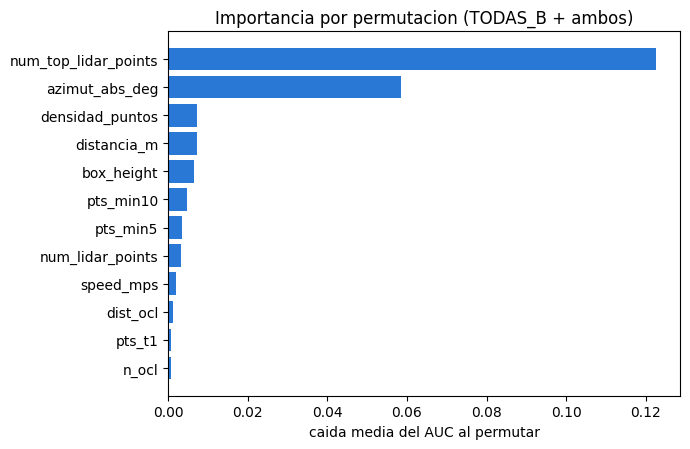

**Lectura (generada).** En el conjunto `TODAS_B + ambos`, las variables que más pesan son `num_top_lidar_points` (0.122), `azimut_abs_deg` (0.059), `densidad_puntos` (0.007), `distancia_m` (0.007), `box_height` (0.006). Las de puntos LiDAR dominan la lista.

In [21]:
cols_mejor = conjuntos[mejor_conjunto]
Xm = bz[cols_mejor].values
rng_p = np.random.default_rng(SEMILLA)
caidas = {c: [] for c in cols_mejor}
for k in FOLDS:
    tr, va = fB != k, fB == k
    m = HistGradientBoostingClassifier(max_iter=150, random_state=SEMILLA).fit(Xm[tr], yB[tr])
    Xv, yv = Xm[va].copy(), yB[va]
    ref = roc_auc_score(yv, m.predict_proba(Xv)[:, 1])
    for j, c in enumerate(cols_mejor):
        for _ in range(3):
            Xp = Xv.copy()
            Xp[:, j] = rng_p.permutation(Xp[:, j])
            caidas[c].append(ref - roc_auc_score(yv, m.predict_proba(Xp)[:, 1]))
imp = pd.Series({c: np.mean(v) for c, v in caidas.items()}).sort_values(ascending=False)
print(f"Importancia por permutacion (caida media de AUC) del conjunto '{mejor_conjunto}':")
print(imp.head(15).round(4).to_string())
imp.to_csv(RUTA_REPORTING / "08_importancia_permutacion.csv", header=["caida_auc"])
RES["importancia"] = imp
fig, ax = plt.subplots(figsize=(7, 4.6))
top = imp.head(12)[::-1]
ax.barh(top.index, top.values, color=AZUL)
ax.set_xlabel("caida media del AUC al permutar"); ax.set_title(f"Importancia por permutacion ({mejor_conjunto})")
fig.tight_layout()
guardar_fig(fig, "08_importancia_permutacion")
plt.show()
display(Markdown(
    f"**Lectura (generada).** En el conjunto `{mejor_conjunto}`, las variables que más pesan son " + ", ".join(f"`{c}` ({v:.3f})" for c, v in imp.head(5).items()) +
    f". Las de puntos LiDAR " + ("dominan" if imp.head(3).index.isin(["num_lidar_points", "num_top_lidar_points", "densidad_puntos", "pts_media5", "pts_media10", "pts_min5", "pts_min10", "pts_t1", "pts_t2"]).sum() >= 2 else "no dominan") + " la lista."))

# D. No supervisado orientado a B (observabilidad)

**Por qué importa.** En el 07 agrupamos peatones y ciclistas por *cómo se mueven* y vimos que eso casi no explica la cobertura de cámara. Acá agrupamos por **qué tan bien observada está la caja** (distancia, puntos, densidad, tamaño y oclusión)
y vemos si algún grupo concentra las lagunas. Criterio fijado antes: silhouette ≥ 0,25, ARI de estabilidad por segmento ≥ 0,80 y rango de la tasa de `sin_camara` entre clusters ≥ 10 puntos con IC que excluya 0.

In [22]:
bz["dist_ocl_f"] = bz["dist_ocl"].fillna(100.0)               # sin oclusor: distancia grande
bz["log_pts"], bz["log_dens"], bz["log_vol"] = np.log1p(bz["num_lidar_points"]), np.log1p(bz["densidad_puntos"]), np.log1p(bz["volumen_caja"])
FEAT_D = ["distancia_m", "azimut_abs_deg", "log_pts", "log_dens", "log_vol", "n_ocl", "frac_cub", "dist_ocl_f"]
Zr = RobustScaler().fit_transform(bz[FEAT_D].values)
rng_d = np.random.default_rng(SEMILLA)
muestra_sil = rng_d.choice(len(Zr), 10000, replace=False)

filas = []
for k in range(2, 9):
    lab = KMeans(k, n_init=5, random_state=SEMILLA).fit_predict(Zr)
    gm = GaussianMixture(k, covariance_type="full", random_state=SEMILLA, max_iter=200).fit(Zr)
    filas.append({"k": k, "silhouette": silhouette_score(Zr[muestra_sil], lab[muestra_sil]), "Davies-Bouldin": davies_bouldin_score(Zr, lab),
                  "Calinski-Harabasz": calinski_harabasz_score(Zr, lab), "BIC GMM": gm.bic(Zr), "tamano cluster mas chico": np.bincount(lab).min() / len(lab)})
sel = pd.DataFrame(filas).set_index("k")
print(sel.round(3).to_string())
K = int(sel["silhouette"].idxmax())
km = KMeans(K, n_init=10, random_state=SEMILLA).fit(Zr)
bz["c_km"] = km.labels_
gm = GaussianMixture(K, covariance_type="full", random_state=SEMILLA, max_iter=200).fit(Zr)
bz["c_gmm"] = gm.predict(Zr)
# Jerarquico (Ward) sobre una muestra de 10.000 filas; el resto se asigna al centroide mas cercano de los clusters de la muestra
aglo = AgglomerativeClustering(n_clusters=K, linkage="ward").fit(Zr[muestra_sil])
cent = np.vstack([Zr[muestra_sil][aglo.labels_ == c].mean(0) for c in range(K)])
bz["c_ag"] = ((Zr[:, None, :] - cent[None, :, :]) ** 2).sum(2).argmin(1)
print(f"\nk elegido por maximo silhouette de KMeans: {K}")
ari_tec = {"KMeans vs GMM": adjusted_rand_score(bz["c_km"], bz["c_gmm"]), "KMeans vs jerarquico": adjusted_rand_score(bz["c_km"], bz["c_ag"]), "GMM vs jerarquico": adjusted_rand_score(bz["c_gmm"], bz["c_ag"])}
print("Concordancia entre tecnicas (ARI):", {k: round(v, 3) for k, v in ari_tec.items()})

# Estabilidad por segmento: se reajusta con segmentos remuestreados y se compara con el agrupamiento de referencia
aris = []
for b_ in range(30):
    ii = np.concatenate([idx_seg[s] for s in rng_d.integers(0, S_N, S_N)])
    ii = rng_d.choice(ii, min(len(ii), 30000), replace=False)
    aris.append(adjusted_rand_score(km.labels_, KMeans(K, n_init=3, random_state=b_).fit(Zr[ii]).predict(Zr)))
ari_estab = float(np.mean(aris))
print(f"Estabilidad por segmento (30 remuestreos): ARI medio {ari_estab:.3f} | minimo {np.min(aris):.3f}")
sel.to_csv(RUTA_REPORTING / "08_clusters_seleccion_k.csv")

   silhouette  Davies-Bouldin  Calinski-Harabasz     BIC GMM  tamano cluster mas chico
k                                                                                     
2       0.387           1.045          35662.010   26856.993                     0.233
3       0.298           1.264          35156.378 -405480.284                     0.232
4       0.251           1.422          29184.669 -453682.143                     0.199
5       0.227           1.480          25839.183 -476166.910                     0.109
6       0.230           1.415          24031.805 -632226.053                     0.105
7       0.229           1.385          23098.912 -610628.975                     0.098
8       0.218           1.418          21563.213 -645946.285                     0.092



k elegido por maximo silhouette de KMeans: 2
Concordancia entre tecnicas (ARI): {'KMeans vs GMM': 0.997, 'KMeans vs jerarquico': 1.0, 'GMM vs jerarquico': 0.997}


Estabilidad por segmento (30 remuestreos): ARI medio 0.953 | minimo 0.301


In [23]:
bic = sel["BIC GMM"].values
caidas_bic = int((np.diff(bic) < 0).sum())
display(Markdown(
    f"**Nota sobre el GMM (generada).** El BIC cae en {caidas_bic} de {len(bic) - 1} pasos de k" + (" (casi monótonamente)" if caidas_bic >= len(bic) - 2 else "") +
    f", con valores de {miles(bic.min())} a {miles(bic.max())}" + (", incluidos valores negativos grandes" if (bic < 0).any() else "") +
    ". Eso probablemente refleja covarianzas degeneradas por variables discretas o casi constantes (`n_ocl`, `frac_cub`, `dist_ocl_f`), no estructura real; "
    "**por eso el BIC no se usa para elegir k** (k se elige con el silhouette de KMeans, como fija el criterio)."))

**Nota sobre el GMM (generada).** El BIC cae en 5 de 6 pasos de k (casi monótonamente), con valores de -645.946 a 26.856, incluidos valores negativos grandes. Eso probablemente refleja covarianzas degeneradas por variables discretas o casi constantes (`n_ocl`, `frac_cub`, `dist_ocl_f`), no estructura real; **por eso el BIC no se usa para elegir k** (k se elige con el silhouette de KMeans, como fija el criterio).

In [24]:
# Cruce de cada cluster con sin_camara (IC 95% por segmentos), probabilidad media predicha y % de ciclistas
def perfil_clusters(col):
    tab, tasas = tasa_ci(bz[col])
    tab["prob_media_modelo"] = pd.Series(s_hgb).groupby(bz[col].values).mean().values
    tab["% ciclistas"] = bz.groupby(col)["es_ciclista"].mean().values * 100
    med = bz.groupby(col)[["distancia_m", "num_lidar_points", "densidad_puntos", "volumen_caja", "n_ocl", "frac_cub"]].median()
    tab = pd.concat([tab, med.set_index(tab.index)], axis=1)
    return tab, tasas


def rango_y_diferencia(tab, tasas):
    # RANGO = mayor tasa menos menor tasa: no tiene signo y su IC por remuestreo es siempre >= 0 (no sirve para decidir si hay diferencia).
    # DIFERENCIA CON SIGNO: con K = 2, cluster 0 menos cluster 1; con K > 2, cluster de mayor tasa del punto menos cluster de menor tasa del punto.
    pt = tab["tasa"].values
    ia, ib = (0, 1) if len(pt) == 2 else (int(np.nanargmax(pt)), int(np.nanargmin(pt)))
    rg_b = (np.nanmax(tasas, axis=1) - np.nanmin(tasas, axis=1)) * 100
    dif_b = (tasas[:, ia] - tasas[:, ib]) * 100
    lo, hi = np.nanpercentile(dif_b, [2.5, 97.5])
    return {"rango": (np.nanmax(pt) - np.nanmin(pt)) * 100, "rango_ic": tuple(np.nanpercentile(rg_b, [2.5, 97.5])), "dif": (pt[ia] - pt[ib]) * 100, "dif_ic": (lo, hi),
            "par": (ia, ib), "excluye0": bool(lo > 0 or hi < 0)}


perfil_km, tasas_km = perfil_clusters("c_km")
rd = rango_y_diferencia(perfil_km, tasas_km)
rango_pp, rango_lo, rango_hi = rd["rango"], rd["rango_ic"][0], rd["rango_ic"][1]

# Nombres segun el perfil (terciles globales de distancia, densidad y oclusion)
q = {c: bz[c].quantile([1 / 3, 2 / 3]).values for c in ["distancia_m", "densidad_puntos", "frac_cub"]}
def nombrar(r):
    d = "cercanos" if r["distancia_m"] <= q["distancia_m"][0] else ("lejanos" if r["distancia_m"] >= q["distancia_m"][1] else "a distancia media")
    de = "poco densos" if r["densidad_puntos"] <= q["densidad_puntos"][0] else ("densos" if r["densidad_puntos"] >= q["densidad_puntos"][1] else "de densidad media")
    oc = " y ocluidos" if r["frac_cub"] >= q["frac_cub"][1] and q["frac_cub"][1] > 0 else (" y sin oclusores" if r["n_ocl"] == 0 else "")
    return f"{d}, {de}{oc}"
perfil_km["nombre"] = perfil_km.apply(nombrar, axis=1)
vista = perfil_km.copy()
vista["tasa"] = [f"{r['tasa'] * 100:.1f} % ({r['lo'] * 100:.1f} a {r['hi'] * 100:.1f})" for _, r in perfil_km.iterrows()]
vista = vista.drop(columns=["lo", "hi"]).round(2)
print(vista[["nombre", "filas", "tasa", "prob_media_modelo", "% ciclistas", "distancia_m", "num_lidar_points", "densidad_puntos", "volumen_caja", "n_ocl", "frac_cub"]].to_string())
perfil_km.to_csv(RUTA_REPORTING / "08_clusters_perfil.csv")
print(f"\nRango (mayor menos menor tasa, sin signo): {rd['rango']:.1f} puntos (IC 95% del remuestreo {rd['rango_ic'][0]:.1f} a {rd['rango_ic'][1]:.1f}; siempre >= 0, no sirve para el criterio)")
print(f"Diferencia con signo (cluster {rd['par'][0]} menos cluster {rd['par'][1]}): {rd['dif']:.1f} puntos (IC 95% por segmentos {rd['dif_ic'][0]:.1f} a {rd['dif_ic'][1]:.1f}; excluye 0: {rd['excluye0']})")

crit_e = CRIT["estructura"]
sil_K = float(sel.loc[K, "silhouette"])
cond_rango = bool(rd["rango"] >= crit_e["rango_tasa_min_pp"] and rd["excluye0"])      # rango >= 10 y el IC de la diferencia con signo excluye 0
util = bool(sil_K >= crit_e["silhouette_min"] and ari_estab >= crit_e["ari_min"] and cond_rango)
RES["no_sup"] = {"ari_min": float(np.min(aris)), "K": K, "sil": sil_K, "ari": ari_estab, "rango": rd["rango"], "rango_ic": rd["rango_ic"], "dif": rd["dif"], "dif_ic": rd["dif_ic"], "par": rd["par"],
                 "util": util, "ari_tec": ari_tec, "cond": [sil_K >= crit_e["silhouette_min"], ari_estab >= crit_e["ari_min"], cond_rango]}

# Opcional: IsolationForest, 1% mas atipico
iso = IsolationForest(contamination=0.01, random_state=SEMILLA).fit(Zr)
atip = iso.predict(Zr) == -1
tasa_at, tasa_resto = yB[atip].mean(), yB[~atip].mean()
RES["iso"] = {"n": int(atip.sum()), "tasa": tasa_at, "tasa_resto": tasa_resto, "segmentos": int(bz.loc[atip, GRUPO].nunique())}
print(f"IsolationForest: {atip.sum()} cajas atipicas (1%) en {bz.loc[atip, GRUPO].nunique()} segmentos | tasa de sin_camara {tasa_at:.3f} vs {tasa_resto:.3f} en el resto")

                                            nombre  filas                  tasa  prob_media_modelo  % ciclistas  distancia_m  num_lidar_points  densidad_puntos  volumen_caja  n_ocl  frac_cub
0  a distancia media, de densidad media y ocluidos  52611  26.1 % (21.8 a 30.6)               0.24         1.03        36.86              31.0            25.37          1.28    2.0       1.0
1        a distancia media, densos y sin oclusores  15944   13.6 % (9.6 a 17.1)               0.14         6.10        27.84              77.0            59.29          1.33    0.0       0.0

Rango (mayor menos menor tasa, sin signo): 12.4 puntos (IC 95% del remuestreo 7.6 a 18.2; siempre >= 0, no sirve para el criterio)
Diferencia con signo (cluster 0 menos cluster 1): 12.4 puntos (IC 95% por segmentos 7.6 a 18.2; excluye 0: True)


IsolationForest: 686 cajas atipicas (1%) en 28 segmentos | tasa de sin_camara 0.803 vs 0.226 en el resto


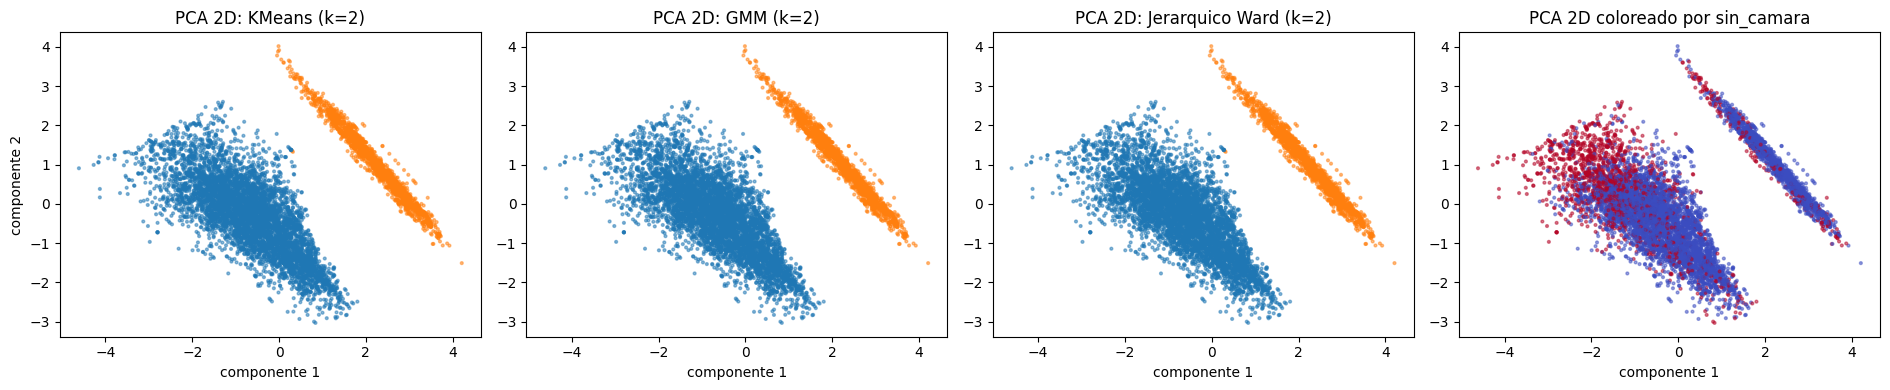

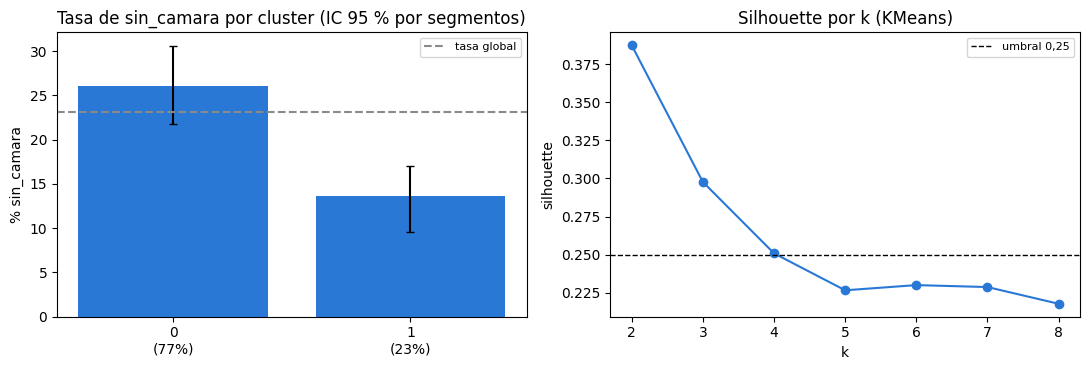

**Lectura (generada).** KMeans con k = 2 (máximo silhouette, 0,387); estabilidad por segmento ARI 0,953 (mínimo de los remuestreos 0,301); concordancia entre técnicas (ARI): KMeans vs GMM 0,997, KMeans vs jerarquico 1,000, GMM vs jerarquico 0,997. Perfiles: cluster 0 (a distancia media, de densidad media y ocluidos): 26,1 % de sin_camara, 77 % de las cajas; cluster 1 (a distancia media, densos y sin oclusores): 13,6 % de sin_camara, 23 % de las cajas. El **rango** de la tasa de `sin_camara` entre clusters (mayor menos menor; no tiene signo, así que su IC siempre es ≥ 0) es de 12,4 puntos (IC 7,6 a 18,2). La **diferencia con signo** (cluster 0 menos cluster 1) es de 12,4 puntos (IC 95 % por segmentos 7,6 a 18,2), y el criterio se evalúa con esta última. Criterio fijado antes: silhouette sí, estabilidad sí, rango sí. **La estructura es útil según el criterio fijado antes.** Las probabilidades medias que predice el modelo por cluster (24,4 %, 14,5 %) siguen de cerca las tasas observadas: el modelo ya captura esa diferencia, así que la estructura describe pero no agrega información predictiva. IsolationForest marca 686 cajas atípicas (1 %) con 80,3 % de `sin_camara` frente a 22,6 % en el resto.

In [25]:
pca = PCA(2, random_state=SEMILLA).fit(Zr)
mm = rng_d.choice(len(Zr), 8000, replace=False)
P2 = pca.transform(Zr[mm])
fig, axes = plt.subplots(1, 4, figsize=(19, 4))
for ax, col, tit in zip(axes[:3], ["c_km", "c_gmm", "c_ag"], [f"KMeans (k={K})", f"GMM (k={K})", f"Jerarquico Ward (k={K})"]):
    ax.scatter(P2[:, 0], P2[:, 1], c=bz[col].values[mm], cmap="tab10", s=4, alpha=0.5, vmin=0, vmax=9)
    ax.set_title("PCA 2D: " + tit); ax.set_xlabel("componente 1")
sc = axes[3].scatter(P2[:, 0], P2[:, 1], c=yB[mm], cmap="coolwarm", s=4, alpha=0.5)
axes[3].set_title("PCA 2D coloreado por sin_camara"); axes[3].set_xlabel("componente 1")
axes[0].set_ylabel("componente 2")
fig.tight_layout()
guardar_fig(fig, "08_clusters_pca")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
x = np.arange(K)
axes[0].bar(x, perfil_km["tasa"] * 100, color=AZUL)
axes[0].errorbar(x, perfil_km["tasa"] * 100, yerr=[(perfil_km["tasa"] - perfil_km["lo"]) * 100, (perfil_km["hi"] - perfil_km["tasa"]) * 100], fmt="none", color="k", capsize=3)
axes[0].axhline(yB.mean() * 100, color=GRIS, ls="--", label="tasa global"); axes[0].legend(fontsize=8)
axes[0].set_xticks(x, [f"{c}\n({perfil_km.loc[str(c), 'filas'] / len(bz):.0%})" for c in range(K)]); axes[0].set_ylabel("% sin_camara"); axes[0].set_title("Tasa de sin_camara por cluster (IC 95 % por segmentos)")
axes[1].plot(sel.index, sel["silhouette"], marker="o", color=AZUL)
axes[1].axhline(CRIT["estructura"]["silhouette_min"], color="k", ls="--", lw=1, label="umbral 0,25"); axes[1].legend(fontsize=8)
axes[1].set_xlabel("k"); axes[1].set_ylabel("silhouette"); axes[1].set_title("Silhouette por k (KMeans)")
fig.tight_layout()
guardar_fig(fig, "08_clusters_tasa")
plt.show()

nd = RES["no_sup"]
nombres_c = "; ".join(f"cluster {c} ({perfil_km.loc[str(c), 'nombre']}): {pct(perfil_km.loc[str(c), 'tasa'])} de sin_camara, {pct(perfil_km.loc[str(c), 'filas'] / len(bz), 0)} de las cajas" for c in range(K))
display(Markdown(
    f"**Lectura (generada).** KMeans con k = {K} (máximo silhouette, {n2(nd['sil'], 3)}); estabilidad por segmento ARI {n2(nd['ari'], 3)} (mínimo de los remuestreos {n2(nd['ari_min'], 3)}); concordancia entre técnicas (ARI): " +
    ", ".join(f"{k} {n2(v, 3)}" for k, v in nd["ari_tec"].items()) + f". Perfiles: {nombres_c}. "
    f"El **rango** de la tasa de `sin_camara` entre clusters (mayor menos menor; no tiene signo, así que su IC siempre es ≥ 0) es de {n2(nd['rango'], 1)} puntos (IC {n2(nd['rango_ic'][0], 1)} a {n2(nd['rango_ic'][1], 1)}). "
    f"La **diferencia con signo** (cluster {nd['par'][0]} menos cluster {nd['par'][1]}) es de {n2(nd['dif'], 1)} puntos (IC 95 % por segmentos {n2(nd['dif_ic'][0], 1)} a {n2(nd['dif_ic'][1], 1)}), y el criterio se evalúa con esta última. "
    f"Criterio fijado antes: silhouette {'sí' if nd['cond'][0] else 'no'}, estabilidad {'sí' if nd['cond'][1] else 'no'}, rango {'sí' if nd['cond'][2] else 'no'}. "
    + ("**La estructura es útil según el criterio fijado antes.**" if nd["util"] else "**La estructura no cumple el criterio de \"útil\"**; la usamos solo como descripción.")
    + f" Las probabilidades medias que predice el modelo por cluster ({', '.join(pct(perfil_km.loc[str(c), 'prob_media_modelo']) for c in range(K))}) " +
    ("siguen de cerca las tasas observadas: el modelo ya captura esa diferencia, así que la estructura describe pero no agrega información predictiva." if np.max(np.abs(perfil_km["prob_media_modelo"] - perfil_km["tasa"])) <= 0.03 else "se apartan de las tasas observadas en algún cluster.")
    + f" IsolationForest marca {RES['iso']['n']} cajas atípicas (1 %) con {pct(RES['iso']['tasa'])} de `sin_camara` frente a {pct(RES['iso']['tasa_resto'])} en el resto."))

## D.1 Exploración con k = 3 y k = 4 (exploratoria)

**Exploratoria:** no cambia la elección del criterio fijado antes (k = 2, máximo silhouette), ni la evaluación de "estructura útil" de arriba. Mismas variables y mismo escalado robusto.
Descriptivamente, llamamos "claramente distinto" a un cluster cuya tasa se aparta ≥ 10 puntos de la tasa global y cuyo IC 95 % por segmentos excluye la tasa global.

In [26]:
explo, tasa_global = {}, yB.mean()
for kx in (3, 4):
    col = f"c_k{kx}"
    bz[col] = KMeans(kx, n_init=10, random_state=SEMILLA).fit_predict(Zr)
    pf, tasas_x = perfil_clusters(col)
    pf["nombre"] = pf.apply(nombrar, axis=1)
    rdx = rango_y_diferencia(pf, tasas_x)
    dg = (pf["tasa"] - tasa_global) * 100
    distintos = [c for c in pf.index if abs(dg.loc[c]) >= 10 and (pf.loc[c, "lo"] > tasa_global or pf.loc[c, "hi"] < tasa_global)]
    cumple = bool(rdx["rango"] >= CRIT["estructura"]["rango_tasa_min_pp"] and rdx["excluye0"])
    explo[kx] = {"perfil": pf, "rd": rdx, "distintos": distintos, "cumple": cumple, "sil": float(sel.loc[kx, "silhouette"])}
    v = pf.copy()
    v["tasa"] = [f"{r['tasa'] * 100:.1f} % ({r['lo'] * 100:.1f} a {r['hi'] * 100:.1f})" for _, r in pf.iterrows()]
    print(f"\nk = {kx} (silhouette {sel.loc[kx, 'silhouette']:.3f}):")
    print(v[["nombre", "filas", "tasa", "prob_media_modelo", "% ciclistas", "distancia_m", "num_lidar_points", "densidad_puntos", "n_ocl", "frac_cub"]].round(2).to_string())
    print(f"Rango {rdx['rango']:.1f} puntos | diferencia con signo (cluster {rdx['par'][0]} menos cluster {rdx['par'][1]}) {rdx['dif']:.1f} (IC {rdx['dif_ic'][0]:.1f} a {rdx['dif_ic'][1]:.1f}) | excluye 0: {rdx['excluye0']}")
pd.concat({f"k{kx}": explo[kx]["perfil"] for kx in explo}, names=["k"]).to_csv(RUTA_REPORTING / "08_clusters_k3_k4.csv")
RES["explo_k"] = {kx: {"distintos": e["distintos"], "cumple": e["cumple"], "rango": e["rd"]["rango"], "dif": e["rd"]["dif"], "dif_ic": e["rd"]["dif_ic"]} for kx, e in explo.items()}
partes = []
for kx, e in explo.items():
    pf = e["perfil"]
    if e["distintos"]:
        det = "; ".join(f"cluster {c} ({pf.loc[c, 'nombre']}, {pct(pf.loc[c, 'filas'] / len(bz), 0)} de las cajas) con {pct(pf.loc[c, 'tasa'])} de `sin_camara` frente a {pct(tasa_global)} global" for c in e["distintos"])
        t1 = f"aparece un grupo con tasa claramente distinta: {det}"
    else:
        t1 = "no aparece ningún grupo con tasa claramente distinta de la global"
    partes.append(f"**k = {kx}:** {t1}; el rango es de {n2(e['rd']['rango'], 1)} puntos y la diferencia con signo de {n2(e['rd']['dif'], 1)} (IC {n2(e['rd']['dif_ic'][0], 1)} a {n2(e['rd']['dif_ic'][1], 1)}), " +
                  ("que **cumple** el rango de 10 puntos con IC que excluye 0." if e["cumple"] else "que **no cumple** el rango de 10 puntos con IC que excluye 0."))
display(Markdown("**Lectura exploratoria (generada).** " + " ".join(partes) + " Es exploratorio: la elección del criterio sigue siendo k = 2."))


k = 3 (silhouette 0.298):
                                      nombre  filas                  tasa  prob_media_modelo  % ciclistas  distancia_m  num_lidar_points  densidad_puntos  n_ocl  frac_cub
0            lejanos, poco densos y ocluidos  27726  39.2 % (32.1 a 47.6)               0.37         1.00        50.64              13.0            10.20    3.0       1.0
1                cercanos, densos y ocluidos  24908   11.4 % (7.8 a 14.4)               0.10         1.07        23.16              83.0            74.25    1.0       1.0
2  a distancia media, densos y sin oclusores  15921   13.6 % (9.6 a 17.1)               0.14         6.11        27.80              78.0            59.48    0.0       0.0
Rango 27.8 puntos | diferencia con signo (cluster 0 menos cluster 1) 27.8 (IC 20.5 a 35.0) | excluye 0: True



k = 4 (silhouette 0.251):
                                            nombre  filas                  tasa  prob_media_modelo  % ciclistas  distancia_m  num_lidar_points  densidad_puntos  n_ocl  frac_cub
0                      cercanos, densos y ocluidos  14813   14.2 % (9.6 a 18.1)               0.14         0.36        17.54             141.0           132.07    1.0       1.0
1        a distancia media, densos y sin oclusores  15904   13.7 % (9.6 a 17.1)               0.14         6.12        27.76              78.0            59.59    0.0       0.0
2  a distancia media, de densidad media y ocluidos  24254   12.7 % (8.9 a 17.5)               0.10         1.50        41.19              31.0            24.95    2.0       1.0
3                  lejanos, poco densos y ocluidos  13584  62.7 % (54.7 a 69.0)               0.62         0.92        53.00               4.0             3.35    3.0       1.0
Rango 50.0 puntos | diferencia con signo (cluster 3 menos cluster 2) 50.0 (IC 42.7 a 57.

**Lectura exploratoria (generada).** **k = 3:** aparece un grupo con tasa claramente distinta: cluster 0 (lejanos, poco densos y ocluidos, 40 % de las cajas) con 39,2 % de `sin_camara` frente a 23,2 % global; cluster 1 (cercanos, densos y ocluidos, 36 % de las cajas) con 11,4 % de `sin_camara` frente a 23,2 % global; el rango es de 27,8 puntos y la diferencia con signo de 27,8 (IC 20,5 a 35,0), que **cumple** el rango de 10 puntos con IC que excluye 0. **k = 4:** aparece un grupo con tasa claramente distinta: cluster 2 (a distancia media, de densidad media y ocluidos, 35 % de las cajas) con 12,7 % de `sin_camara` frente a 23,2 % global; cluster 3 (lejanos, poco densos y ocluidos, 20 % de las cajas) con 62,7 % de `sin_camara` frente a 23,2 % global; el rango es de 50,0 puntos y la diferencia con signo de 50,0 (IC 42,7 a 57,0), que **cumple** el rango de 10 puntos con IC que excluye 0. Es exploratorio: la elección del criterio sigue siendo k = 2.

## D.2 Clusters de k = 2, 3 y 4 frente a la franja 100–120 (continuación de A.6)

Qué parte de cada cluster cae en la franja 100–120 y cuál es su tasa de `sin_camara` excluyéndola. Responde si el cluster "lejanos, poco densos y ocluidos" es sobre todo la franja de azimut.

In [27]:
en_franja = (bz["azimut_abs_deg"] > 100).values
cols_k = {"k = 2": ("c_km", perfil_km), "k = 3": ("c_k3", explo[3]["perfil"]), "k = 4": ("c_k4", explo[4]["perfil"])}
filas, ref_nombre = [], "lejanos, poco densos y ocluidos"
detalle = {}
for kn, (col, pf) in cols_k.items():
    t_sin, _ = tasa_ci(bz[col].where(~en_franja).astype("Int64"))
    for c in pf.index:
        m = (bz[col].astype(str) == str(c)).values
        fila = {"k": kn, "cluster": c, "nombre": pf.loc[c, "nombre"], "filas": int(m.sum()), "% del cluster en 100-120": en_franja[m].mean() * 100,
                "% de la franja que es del cluster": m[en_franja].mean() * 100, "tasa con franja (%)": yB[m].mean() * 100,
                "tasa sin franja (%)": t_sin.loc[str(c), "tasa"] * 100, "IC sin franja": f"{t_sin.loc[str(c), 'lo'] * 100:.1f} a {t_sin.loc[str(c), 'hi'] * 100:.1f}"}
        filas.append(fila)
        if pf.loc[c, "nombre"] == ref_nombre:
            detalle[kn] = fila
tabla_d2 = pd.DataFrame(filas)
print(tabla_d2.round(1).to_string(index=False))
tabla_d2.to_csv(RUTA_REPORTING / "08_clusters_vs_franja.csv", index=False)
RES["d2"] = detalle
if detalle:
    partes = [f"con {kn}, el cluster {d['cluster']} ({d['nombre']}, {miles(d['filas'])} filas) tiene el {pct(d['% del cluster en 100-120'] / 100)} de sus filas en 100–120, y esas filas son el {pct(d['% de la franja que es del cluster'] / 100)} de la franja; "
              f"su tasa de `sin_camara` es {n2(d['tasa con franja (%)'], 1)} % con la franja y {n2(d['tasa sin franja (%)'], 1)} % sin ella (IC {d['IC sin franja']})" for kn, d in detalle.items()]
    mayor = max(d["% del cluster en 100-120"] for d in detalle.values())
    texto = ("**Lectura (generada).** " + "; ".join(partes) + ". " +
             ("**El cluster es sobre todo la franja de azimut** (más de la mitad de sus filas está en 100–120)." if mayor > 50 else
              f"**El cluster no es sobre todo la franja de azimut**: como máximo el {n2(mayor, 1)} % de sus filas está en 100–120, y sin la franja su tasa sigue siendo alta."))
else:
    texto = "**Lectura (generada).** Ningún cluster de k = 2, 3 o 4 tiene el perfil \"lejanos, poco densos y ocluidos\"."
display(Markdown(texto))

    k cluster                                          nombre  filas  % del cluster en 100-120  % de la franja que es del cluster  tasa con franja (%)  tasa sin franja (%) IC sin franja
k = 2       0 a distancia media, de densidad media y ocluidos  52611                       5.0                               64.8                 26.1                 23.9   19.5 a 28.4
k = 2       1       a distancia media, densos y sin oclusores  15944                       8.9                               35.2                 13.6                  9.6    5.9 a 12.7
k = 3       0                 lejanos, poco densos y ocluidos  27726                       1.5                               10.4                 39.2                 38.5   31.1 a 46.7
k = 3       1                     cercanos, densos y ocluidos  24908                       8.8                               54.4                 11.4                  6.4     4.6 a 8.3
k = 3       2       a distancia media, densos y sin oclusores  15921  

**Lectura (generada).** con k = 3, el cluster 0 (lejanos, poco densos y ocluidos, 27.726 filas) tiene el 1,5 % de sus filas en 100–120, y esas filas son el 10,4 % de la franja; su tasa de `sin_camara` es 39,2 % con la franja y 38,5 % sin ella (IC 31.1 a 46.7); con k = 4, el cluster 3 (lejanos, poco densos y ocluidos, 13.584 filas) tiene el 2,9 % de sus filas en 100–120, y esas filas son el 9,7 % de la franja; su tasa de `sin_camara` es 62,7 % con la franja y 61,9 % sin ella (IC 53.6 a 68.2). **El cluster no es sobre todo la franja de azimut**: como máximo el 2,9 % de sus filas está en 100–120, y sin la franja su tasa sigue siendo alta.

# E. Conclusiones

**Por qué importa.** Resume qué aprendimos sobre `sin_camara`, qué proponemos llevar al 09 y qué queda abierto. Es una propuesta con la evidencia a la vista; **no entrena el modelo final ni elige puntos de operación**.

In [28]:
u, pr_, sg, cj, ns, ip = RES["umbral"], RES["pareado"], RES["segmento"], RES["conjuntos"], RES["no_sup"], RES["iso"]
tc = cj["tabla"]
conjunto_09 = cj["conjunto_09"]
m_h, m_r = metricas_score(yB, s_hgb, tb_f), metricas_score(yB, s_regla, tb_f)
tasa_clase = bz.groupby("object_type")["sin"].agg(["mean", "size"])
objs = bz.groupby([GRUPO, "key.laser_object_id"])["sin"].mean()
share_mixto = float(((objs > 0) & (objs < 1)).mean())
cap_modelo = bool(np.max(np.abs(perfil_km["prob_media_modelo"] - perfil_km["tasa"])) <= 0.03)

parrafos = [
    f"**Qué produce `sin_camara`.** La tasa va de {pct(RES['tasa_fijo']['tasa'].iloc[0])} con {RES['tasa_fijo'].index[0]} puntos a {pct(RES['tasa_fijo']['tasa'].iloc[-1])} con {RES['tasa_fijo'].index[-1]}. "
    + (f"Hay un umbral marcado cerca de {int(np.floor(u['mediana']))} puntos (AUC del corte único {n2(u['auc_corte'], 3)} frente a {n2(u['auc_continua'], 3)} de la regla continua)." if u["marcado"]
       else f"El cambio es gradual: el mejor corte único ({int(np.floor(u['mediana']))} puntos) logra AUC {n2(u['auc_corte'], 3)} frente a {n2(u['auc_continua'], 3)} de la regla continua y su ubicación varía entre folds.")
    + f" Dentro de un mismo objeto, el {pct(pr_['frac'])} de los objetos mixtos tiene más puntos en los frames con par 2D (Wilcoxon p = {pr_['p']:.1e}), aunque la distancia también cambia.",
    f"**Robustez.** La mediana del AUC por segmento del HGB es {n2(sg['mediana']['HGB'], 3)} (IQR {n2(sg['q1']['HGB'], 3)}–{n2(sg['q3']['HGB'], 3)}, {sg['n']} segmentos evaluables) frente a {n2(sg['agrupado']['HGB'], 3)} agrupado; "
    f"la regla simple tiene {n2(sg['mediana'][REGLA], 3)} por segmento y {n2(sg['agrupado'][REGLA], 3)} agrupado.",
    f"**Variables nuevas.** " + (f"Ayudan según el criterio fijado antes: {', '.join(cj['ayudan'])}." if cj["ayudan"] else
                              "Ningún conjunto cumple el criterio fijado antes (ΔAUC ≥ 0,01 y fracción para 80 % −2 puntos con IC que excluya 0): la regla \"pocos puntos\" explica casi todo y el modelo agrega solo la parte ya medida en el 07.")
    + f" Mejor AUC: {cj['mejor']} ({n2(tc.loc[cj['mejor'], 'AUC'], 3)}).",
    f"**No supervisado.** k = {ns['K']}, silhouette {n2(ns['sil'], 3)}, estabilidad ARI {n2(ns['ari'], 3)} (mínimo {n2(ns['ari_min'], 3)}), rango de la tasa entre clusters {n2(ns['rango'], 1)} puntos y diferencia con signo de {n2(ns['dif'], 1)} puntos (IC {n2(ns['dif_ic'][0], 1)} a {n2(ns['dif_ic'][1], 1)}): "
    + ("estructura útil según el criterio" if ns["util"] else "no cumple el criterio de estructura útil; sirve solo como descripción")
    + ("; las probabilidades del modelo ya siguen esas tasas, así que describe pero no agrega información predictiva." if cap_modelo else "."),
]
llevar = (f"**Qué llevar al 09.** Variables: `{conjunto_09}` (conjunto {'propuesto por el criterio' if cj['ayudan'] else 'base, porque ningún conjunto ampliado cumplió el criterio'}). "
          f"Modelos: la regresión logística y el HGB se comparan en el 09 (AUC agrupado HGB {n2(auc_base['HGB'], 3)} contra regresión logística {n2(auc_base['Regresion logistica'], 3)}; "
          f"mediana del AUC por segmento HGB {n2(sg['mediana']['HGB'], 3)} contra regresión logística {n2(sg['mediana']['Regresion logistica'], 3)}), siempre contra la regla simple de menos puntos LiDAR primero "
          f"(AUC {n2(auc_base[REGLA], 3)}), que es la alternativa realista; **la decisión se toma ahí**. "
          f"Las variables quedan en `data/05_model_input/features_B.parquet` y los conjuntos en `config_features_B.json`.")
texto_e = "\n\n".join(parrafos) + "\n\n" + llevar
display(Markdown(texto_e))

**Qué produce `sin_camara`.** La tasa va de 80,5 % con 0-5 puntos a 9,4 % con >100. El cambio es gradual: el mejor corte único (7 puntos) logra AUC 0,665 frente a 0,797 de la regla continua y su ubicación varía entre folds. Dentro de un mismo objeto, el 80,0 % de los objetos mixtos tiene más puntos en los frames con par 2D (Wilcoxon p = 1.9e-29), aunque la distancia también cambia.

**Robustez.** La mediana del AUC por segmento del HGB es 0,864 (IQR 0,818–0,913, 16 segmentos evaluables) frente a 0,854 agrupado; la regla simple tiene 0,802 por segmento y 0,797 agrupado.

**Variables nuevas.** Ningún conjunto cumple el criterio fijado antes (ΔAUC ≥ 0,01 y fracción para 80 % −2 puntos con IC que excluya 0): la regla "pocos puntos" explica casi todo y el modelo agrega solo la parte ya medida en el 07. Mejor AUC: TODAS_B + ambos (0,861).

**No supervisado.** k = 2, silhouette 0,387, estabilidad ARI 0,953 (mínimo 0,301), rango de la tasa entre clusters 12,4 puntos y diferencia con signo de 12,4 puntos (IC 7,6 a 18,2): estructura útil según el criterio; las probabilidades del modelo ya siguen esas tasas, así que describe pero no agrega información predictiva.

**Qué llevar al 09.** Variables: `TODAS_B` (conjunto base, porque ningún conjunto ampliado cumplió el criterio). Modelos: la regresión logística y el HGB se comparan en el 09 (AUC agrupado HGB 0,854 contra regresión logística 0,838; mediana del AUC por segmento HGB 0,864 contra regresión logística 0,873), siempre contra la regla simple de menos puntos LiDAR primero (AUC 0,797), que es la alternativa realista; **la decisión se toma ahí**. Las variables quedan en `data/05_model_input/features_B.parquet` y los conjuntos en `config_features_B.json`.

## E.1 Hallazgos que conviene mostrar en el informe técnico

In [29]:
caida = RES["caida"]
hallazgos = [
    f"La etiqueta `sin_camara` depende sobre todo de los puntos LiDAR: la tasa cae de {pct(RES['tasa_fijo']['tasa'].iloc[0])} con {RES['tasa_fijo'].index[0]} puntos a {pct(RES['tasa_fijo']['tasa'].iloc[-1])} con {RES['tasa_fijo'].index[-1]}, "
    f"y a distancia fija la diferencia entre pocos y muchos puntos va de {n2(caida[0], 1)} a {n2(caida[1], 1)} puntos porcentuales (A.1 y A.2).",
    f"Dentro de un mismo objeto, el {pct(pr_['frac'])} de los {pr_['objetos']} objetos mixtos tiene más puntos cuando la cámara sí lo confirma (A.4): el número de puntos acompaña el cambio de estado.",
    f"Una regla sin modelo (menos puntos LiDAR primero) ya da AUC {n2(auc_base[REGLA], 3)}; el HGB, {n2(auc_base['HGB'], 3)}. Para cubrir el 80 % de las lagunas hay que revisar el {pct(m_h['Fraccion para 80%'])} de los frames con el HGB y el {pct(m_r['Fraccion para 80%'])} con la regla (B y 07).",
    f"El AUC dentro de cada segmento (mediana {n2(sg['mediana']['HGB'], 3)}, {sg['n']} segmentos evaluables) es parecido al agrupado ({n2(sg['agrupado']['HGB'], 3)}): el resultado no depende de mezclar segmentos (B).",
    ("Las variables temporales y de oclusión no cumplen el criterio de mejora: la información de observabilidad ya está en los puntos LiDAR y la geometría (C)." if not cj["ayudan"] else f"Mejoran según el criterio: {', '.join(cj['ayudan'])} (C)."),
    f"Los ciclistas casi siempre tienen par 2D: `sin_camara` en {pct(tasa_clase.loc['CYCLIST', 'mean'])} de sus {miles(tasa_clase.loc['CYCLIST', 'size'])} filas, frente a {pct(tasa_clase.loc['PEDESTRIAN', 'mean'])} en peatones (hallazgo no esperado; pocos ciclistas, ver limitaciones).",
    f"El 1 % de cajas más atípicas (IsolationForest, {miles(ip['n'])} cajas en {ip['segmentos']} segmentos) tiene {pct(ip['tasa'])} de `sin_camara`, frente a {pct(ip['tasa_resto'])} en el resto (D).",
    f"**La ausencia de par 2D en {AZ_MAX}–{ZONA_CAMARAS_DEG}° es en buena parte geométrica:** la tasa de `sin_camara` es {pct(RES['a6']['tasa_resto'])} con |azimut| ≤ {AZ_MAX}° y {pct(RES['a6']['tasa_banda'])} en la franja (que reúne el {pct(RES['a6']['share_banda'])} de las filas de B), "
    f"y en el último bin de 5° llega a {pct(t5['tasa'].iloc[-1])} con {miles(t5['filas'].iloc[-1])} filas. Solo el {pct(RES['a7']['frac_fuera_az_max'])} de las cajas con par 2D en train está más allá de {AZ_MAX}°. "
    f"Sin la franja, el HGB deja de superar a la regla de puntos (AUC {n2(res_pob['sin la franja 100-120'][0]['HGB']['AUC'], 3)} contra {n2(res_pob['sin la franja 100-120'][0][REGLA]['AUC'], 3)}; A.6 y A.7).",
]
display(Markdown("\n".join(f"{i + 1}. {h}" for i, h in enumerate(hallazgos))))

1. La etiqueta `sin_camara` depende sobre todo de los puntos LiDAR: la tasa cae de 80,5 % con 0-5 puntos a 9,4 % con >100, y a distancia fija la diferencia entre pocos y muchos puntos va de 71,7 a 87,1 puntos porcentuales (A.1 y A.2).
2. Dentro de un mismo objeto, el 80,0 % de los 460 objetos mixtos tiene más puntos cuando la cámara sí lo confirma (A.4): el número de puntos acompaña el cambio de estado.
3. Una regla sin modelo (menos puntos LiDAR primero) ya da AUC 0,797; el HGB, 0,854. Para cubrir el 80 % de las lagunas hay que revisar el 39,1 % de los frames con el HGB y el 50,5 % con la regla (B y 07).
4. El AUC dentro de cada segmento (mediana 0,864, 16 segmentos evaluables) es parecido al agrupado (0,854): el resultado no depende de mezclar segmentos (B).
5. Las variables temporales y de oclusión no cumplen el criterio de mejora: la información de observabilidad ya está en los puntos LiDAR y la geometría (C).
6. Los ciclistas casi siempre tienen par 2D: `sin_camara` en 8,8 % de sus 1.516 filas, frente a 23,5 % en peatones (hallazgo no esperado; pocos ciclistas, ver limitaciones).
7. El 1 % de cajas más atípicas (IsolationForest, 686 cajas en 28 segmentos) tiene 80,3 % de `sin_camara`, frente a 22,6 % en el resto (D).
8. **La ausencia de par 2D en 100–120° es en buena parte geométrica:** la tasa de `sin_camara` es 20,7 % con |azimut| ≤ 100° y 62,2 % en la franja (que reúne el 5,9 % de las filas de B), y en el último bin de 5° llega a 100,0 % con 1.133 filas. Solo el 2,6 % de las cajas con par 2D en train está más allá de 100°. Sin la franja, el HGB deja de superar a la regla de puntos (AUC 0,835 contra 0,858; A.6 y A.7).

## E.2 Preguntas abiertas para el 09

No se resuelven acá. Los números de cada pregunta salen de este notebook y solo sirven de contexto.

In [30]:
def auc_grupo(col):
    out = {}
    for v in sorted(bz[col].unique()):
        m = (bz[col] == v).values
        if min(yB[m].sum(), (1 - yB[m]).sum()) >= CRIT["auc_segmento"]["min_filas_clase"]:
            out[v] = roc_auc_score(yB[m], s_hgb[m])
    return out
auc_td, auc_loc = auc_grupo("time_of_day"), auc_grupo("location")
f_ = lambda d: ", ".join(f"{k} {n2(v, 3)}" for k, v in d.items())
rf = por_fold(yB, s_hgb, fB)[:, 0]
preguntas = [
    f"**Puntos de operación.** ¿Qué recall objetivo y qué fracción de frames revisar? El HGB captura el {pct(m_h['Captura@20%'])} de las lagunas con el 20 % de los frames y exige revisar el {pct(m_h['Fraccion para 80%'])} para cubrir el 80 %; el punto concreto y su IC se definen en el 09.",
    f"**Calibración.** La probabilidad media predicha por el HGB fuera de fold es {n2(s_hgb.mean(), 3)} frente a una prevalencia de {n2(yB.mean(), 3)}. ¿Hace falta calibrar (curva de calibración, Brier) antes de fijar umbrales de probabilidad?",
    f"**Equidad.** AUC del HGB por momento del día: {f_(auc_td)}; por ubicación: {f_(auc_loc)}. ¿Qué brecha es aceptable y cómo se mide si el test tiene un solo segmento Night y uno Dawn/Dusk (ver 07, Sección 11)?",
    f"**Unidad de revisión.** El {pct(share_mixto)} de los objetos es mixto: ¿frame u objeto? A nivel de frame el modelo prioriza; a nivel de objeto casi no (ver 07, Sección 8.4).",
    f"**Variabilidad entre segmentos.** El AUC del HGB por segmento va de {n2(res_seg.loc['HGB', 'min'], 3)} a {n2(res_seg.loc['HGB', 'max'], 3)} y por fold de {n2(rf.min(), 3)} a {n2(rf.max(), 3)}. ¿Cómo reportar la incertidumbre sin reducirla a un solo número?",
    f"**Modelo frente a la regla.** La regresión logística ({n2(auc_base['Regresion logistica'], 3)}) y el HGB ({n2(auc_base['HGB'], 3)}) superan a la regla simple ({n2(auc_base[REGLA], 3)}); para cubrir el 80 % de las lagunas hay que revisar el {pct(m_h['Fraccion para 80%'])} de los frames con el HGB y el {pct(m_r['Fraccion para 80%'])} con la regla. ¿Qué regularización, pesos de clase y complejidad corresponden a cada modelo y cuál de los dos se prefiere?",
    f"**Ciclistas.** Solo {miles(tasa_clase.loc['CYCLIST', 'size'])} filas de ciclistas en B: ¿se reporta por clase y con qué cautela?",
    f"**Zona de cámaras (decisión tomada).** La población principal pasó de {ZONA_CAMARAS_DEG} a **{AZ_MAX} grados** por el hallazgo de A.6: la franja {AZ_MAX}–{ZONA_CAMARAS_DEG}° reúne el {pct(RES['a6']['share_banda'])} de las filas de B con {pct(RES['a6']['tasa_banda'])} de `sin_camara`, frente a {pct(RES['a6']['tasa_resto'])} con azimut ≤ {AZ_MAX}°, "
    f"y sin ella la Fracción para 80 % del HGB pasa de {pct(RES['a6']['f80_full'])} a {pct(RES['a6']['f80_excl'])} y la diferencia HGB menos regla de {RES['a6']['dif'][('B completa', 'Fraccion para 80%')][0] * 100:+.1f} a {RES['a6']['dif'][('sin la franja 100-120', 'Fraccion para 80%')][0] * 100:+.1f} puntos. "
    f"Queda abierto confirmar el borde con `camera_calibration` (no disponible localmente), que daría el yaw y el campo de visión de cada cámara.",
]
RES["preguntas"] = preguntas
display(Markdown("\n".join(f"{i + 1}. {q}" for i, q in enumerate(preguntas))))

1. **Puntos de operación.** ¿Qué recall objetivo y qué fracción de frames revisar? El HGB captura el 61,3 % de las lagunas con el 20 % de los frames y exige revisar el 39,1 % para cubrir el 80 %; el punto concreto y su IC se definen en el 09.
2. **Calibración.** La probabilidad media predicha por el HGB fuera de fold es 0,221 frente a una prevalencia de 0,232. ¿Hace falta calibrar (curva de calibración, Brier) antes de fijar umbrales de probabilidad?
3. **Equidad.** AUC del HGB por momento del día: Dawn/Dusk 0,798, Day 0,873, Night 0,873; por ubicación: location_other 0,912, location_phx 0,866, location_sf 0,851. ¿Qué brecha es aceptable y cómo se mide si el test tiene un solo segmento Night y uno Dawn/Dusk (ver 07, Sección 11)?
4. **Unidad de revisión.** El 83,0 % de los objetos es mixto: ¿frame u objeto? A nivel de frame el modelo prioriza; a nivel de objeto casi no (ver 07, Sección 8.4).
5. **Variabilidad entre segmentos.** El AUC del HGB por segmento va de 0,626 a 0,971 y por fold de 0,824 a 0,888. ¿Cómo reportar la incertidumbre sin reducirla a un solo número?
6. **Modelo frente a la regla.** La regresión logística (0,838) y el HGB (0,854) superan a la regla simple (0,797); para cubrir el 80 % de las lagunas hay que revisar el 39,1 % de los frames con el HGB y el 50,5 % con la regla. ¿Qué regularización, pesos de clase y complejidad corresponden a cada modelo y cuál de los dos se prefiere?
7. **Ciclistas.** Solo 1.516 filas de ciclistas en B: ¿se reporta por clase y con qué cautela?
8. **Zona de cámaras (decisión tomada).** La población principal pasó de 120 a **100 grados** por el hallazgo de A.6: la franja 100–120° reúne el 5,9 % de las filas de B con 62,2 % de `sin_camara`, frente a 20,7 % con azimut ≤ 100°, y sin ella la Fracción para 80 % del HGB pasa de 39,1 % a 40,9 % y la diferencia HGB menos regla de -11.4 a +2.4 puntos. Queda abierto confirmar el borde con `camera_calibration` (no disponible localmente), que daría el yaw y el campo de visión de cada cámara.

In [31]:
# Documento y resumen ejecutivo generados
limit = [
    f"La oclusión es una aproximación angular que ignora la altura de las cajas y la transparencia de señales; {pct((bz['n_ocl'] > 0).mean(), 0)} de las cajas tiene al menos un oclusor.",
    "Las variables temporales usan solo frames anteriores del mismo track.",
    "Los folds se estratificaron por `tiene_camara`, no por `sin_camara` en la zona de cámaras.",
    f"Los resultados describen cobertura de etiquetado en {len(SEGS_TRAIN)} segmentos de train y no visibilidad física de la cámara.",
]
md_doc = f'''### Análisis de observabilidad de `sin_camara` (notebook 08)

Solo segmentos de train y sus folds; el test no se usó. Criterios fijados antes de correr (Sección 0 del notebook).

{texto_e}

**Variables nuevas evaluadas**

{md_tabla(vista_c.reset_index(), indice=False)}

**Hallazgos para el informe técnico**

''' + "\n".join(f"{i + 1}. {h}" for i, h in enumerate(hallazgos)) + f'''

**Preguntas abiertas para el 09**

''' + "\n".join(f"{i + 1}. {q}" for i, q in enumerate(preguntas)) + '''

**Limitaciones**

''' + "\n".join(f"- {l}" for l in limit) + "\n"
(RUTA_DOCS / "analisis_observabilidad_B.md").write_text(md_doc, encoding="utf-8")

resumen = f'''{parrafos[0]}

**Puntos clave**

1. {parrafos[1]}
2. {parrafos[2]}
3. {parrafos[3]}

{llevar}

Este notebook no entrena el modelo final ni elige puntos de operación; es insumo del 09.'''
(RUTA_REPORTING / "resumen_ejecutivo_08.md").write_text(resumen, encoding="utf-8")
print(f"Escritos docs/analisis_observabilidad_B.md ({len(md_doc)} caracteres) y el resumen ejecutivo")
display(Markdown("## Resumen ejecutivo generado\n\n" + resumen))

Escritos docs/analisis_observabilidad_B.md (6860 caracteres) y el resumen ejecutivo


## Resumen ejecutivo generado

**Qué produce `sin_camara`.** La tasa va de 80,5 % con 0-5 puntos a 9,4 % con >100. El cambio es gradual: el mejor corte único (7 puntos) logra AUC 0,665 frente a 0,797 de la regla continua y su ubicación varía entre folds. Dentro de un mismo objeto, el 80,0 % de los objetos mixtos tiene más puntos en los frames con par 2D (Wilcoxon p = 1.9e-29), aunque la distancia también cambia.

**Puntos clave**

1. **Robustez.** La mediana del AUC por segmento del HGB es 0,864 (IQR 0,818–0,913, 16 segmentos evaluables) frente a 0,854 agrupado; la regla simple tiene 0,802 por segmento y 0,797 agrupado.
2. **Variables nuevas.** Ningún conjunto cumple el criterio fijado antes (ΔAUC ≥ 0,01 y fracción para 80 % −2 puntos con IC que excluya 0): la regla "pocos puntos" explica casi todo y el modelo agrega solo la parte ya medida en el 07. Mejor AUC: TODAS_B + ambos (0,861).
3. **No supervisado.** k = 2, silhouette 0,387, estabilidad ARI 0,953 (mínimo 0,301), rango de la tasa entre clusters 12,4 puntos y diferencia con signo de 12,4 puntos (IC 7,6 a 18,2): estructura útil según el criterio; las probabilidades del modelo ya siguen esas tasas, así que describe pero no agrega información predictiva.

**Qué llevar al 09.** Variables: `TODAS_B` (conjunto base, porque ningún conjunto ampliado cumplió el criterio). Modelos: la regresión logística y el HGB se comparan en el 09 (AUC agrupado HGB 0,854 contra regresión logística 0,838; mediana del AUC por segmento HGB 0,864 contra regresión logística 0,873), siempre contra la regla simple de menos puntos LiDAR primero (AUC 0,797), que es la alternativa realista; **la decisión se toma ahí**. Las variables quedan en `data/05_model_input/features_B.parquet` y los conjuntos en `config_features_B.json`.

Este notebook no entrena el modelo final ni elige puntos de operación; es insumo del 09.